# Heart Disease Prediction — Modelling & Evaluation

**Author:** Vyshnavi Sunil Kumar  
**Dataset:** Heart Failure Prediction (Kaggle / UCI)  
**Notebook:** 02 of 02 — Machine Learning Models & Comparison

---

## Overview

This notebook builds on the cleaned and preprocessed data from Notebook 01. 
We implement seven machine learning algorithms covering the full spectrum 
of techniques — from unsupervised clustering to deep learning — and 
conclude with a rigorous statistical comparison to select the best model.

---

## Techniques Covered

| Topic | Algorithm |
|---|---|
| Unsupervised Learning | K-Means, Hierarchical Clustering |
| Regression | Linear Regression |
| Classification | Logistic Regression |
| Nearest Neighbours | KNN Classifier |
| Decision Trees | Decision Tree Classifier |
| Ensemble Methods | Random Forest, Gradient Boosting |
| Probabilistic | Naive Bayes |
| Deep Learning | Neural Network (MLP) |
| Model Evaluation | K-Fold CV, Paired t-test |

---

## Input
Preprocessed data saved from Notebook 01:
- `heart_cleaned_encoded.csv` — cleaned and encoded dataset
- All features already scaled using StandardScaler
- Train/test split: 80/20 stratified

## 1. Importing Libraries & Loading Data

We import all required libraries and reload the cleaned encoded dataset 
saved from Notebook 01. We reconstruct the identical 80/20 stratified 
train/test split using `random_state=42` — this guarantees every model 
is evaluated on exactly the same data, making comparisons fair.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage
from itertools import combinations
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (10, 6)
sns.set_theme(style='whitegrid')

# Load cleaned encoded data
df = pd.read_csv('../data/heart_cleaned_encoded.csv')

# Separate features and target
X = df.drop('HeartDisease', axis=1)
y = df['HeartDisease']

# Split BEFORE scaling — fit the scaler on the training fold only, so no
# test-set statistics leak into preprocessing.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train_raw), columns=X.columns, index=X_train_raw.index)
X_test  = pd.DataFrame(scaler.transform(X_test_raw),      columns=X.columns, index=X_test_raw.index)

# Separate full-dataset scaled view, used ONLY for the unsupervised clustering
# section below — never for supervised train/test scoring, where scaling must
# stay inside the split (or inside each CV fold via a Pipeline, as used later).
X_scaled_full = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns)

print(f"Dataset loaded: {df.shape}")
print(f"Features: {X.shape[1]}")
print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")
print("\n✅ Ready for modelling")

Dataset loaded: (917, 19)
Features: 18
Training set: (733, 18)
Test set: (184, 18)

✅ Ready for modelling


## 2. Feature Selection — SelectKBest

Before building any models, we use **SelectKBest** to identify which 
features are most statistically relevant to the target variable.

### How SelectKBest works
SelectKBest evaluates each feature **independently** against the target 
using a scoring function and keeps only the top K features. We use 
**f_classif** — the ANOVA F-test — which measures whether the means 
of each feature differ significantly across the two classes (No Disease 
vs Has Disease).

A high F-score means the feature distributions differ greatly between 
classes — that feature is highly discriminative.

### Choosing optimal K
We cannot just pick K arbitrarily. Instead we:
1. Try every value of K from 1 to 18 (all features)
2. For each K, evaluate a Logistic Regression model using 5-fold CV
3. Plot CV accuracy vs K
4. Select the K that gives the highest CV accuracy

This ensures we keep enough features to capture the signal without 
including noisy ones that hurt generalisation.

### Why feature selection matters
- Removes irrelevant or redundant features that add noise
- Reduces model complexity and training time
- Can improve generalisation on unseen data
- Helps interpret which features drive predictions

Feature F-Scores (ranked):
          Feature    F-Score      P-Value
      ST_Slope_Up 508.318854 7.343488e-86
    ST_Slope_Flat 343.343989 3.937233e-63
ChestPainType_ASY 267.538253 1.771002e-51
   ExerciseAngina 220.259058 9.531445e-44
            MaxHR 138.385479 2.215614e-29
ChestPainType_ATA 136.163938 5.682469e-29
          Oldpeak 120.597294 4.486788e-26
              Sex  69.492542 3.795161e-16
        FastingBS  57.181348 1.194512e-13
              Age  43.545914 7.952629e-11
ChestPainType_NAP  36.824959 2.073930e-09
    ST_Slope_Down  15.121849 1.099690e-04
RestingECG_Normal   9.936341 1.686657e-03
        RestingBP   8.268134 4.152015e-03
    RestingECG_ST   8.160056 4.403864e-03
 ChestPainType_TA   2.804917 9.440341e-02
      Cholesterol   1.431881 2.318457e-01
   RestingECG_LVH   1.044852 3.070338e-01


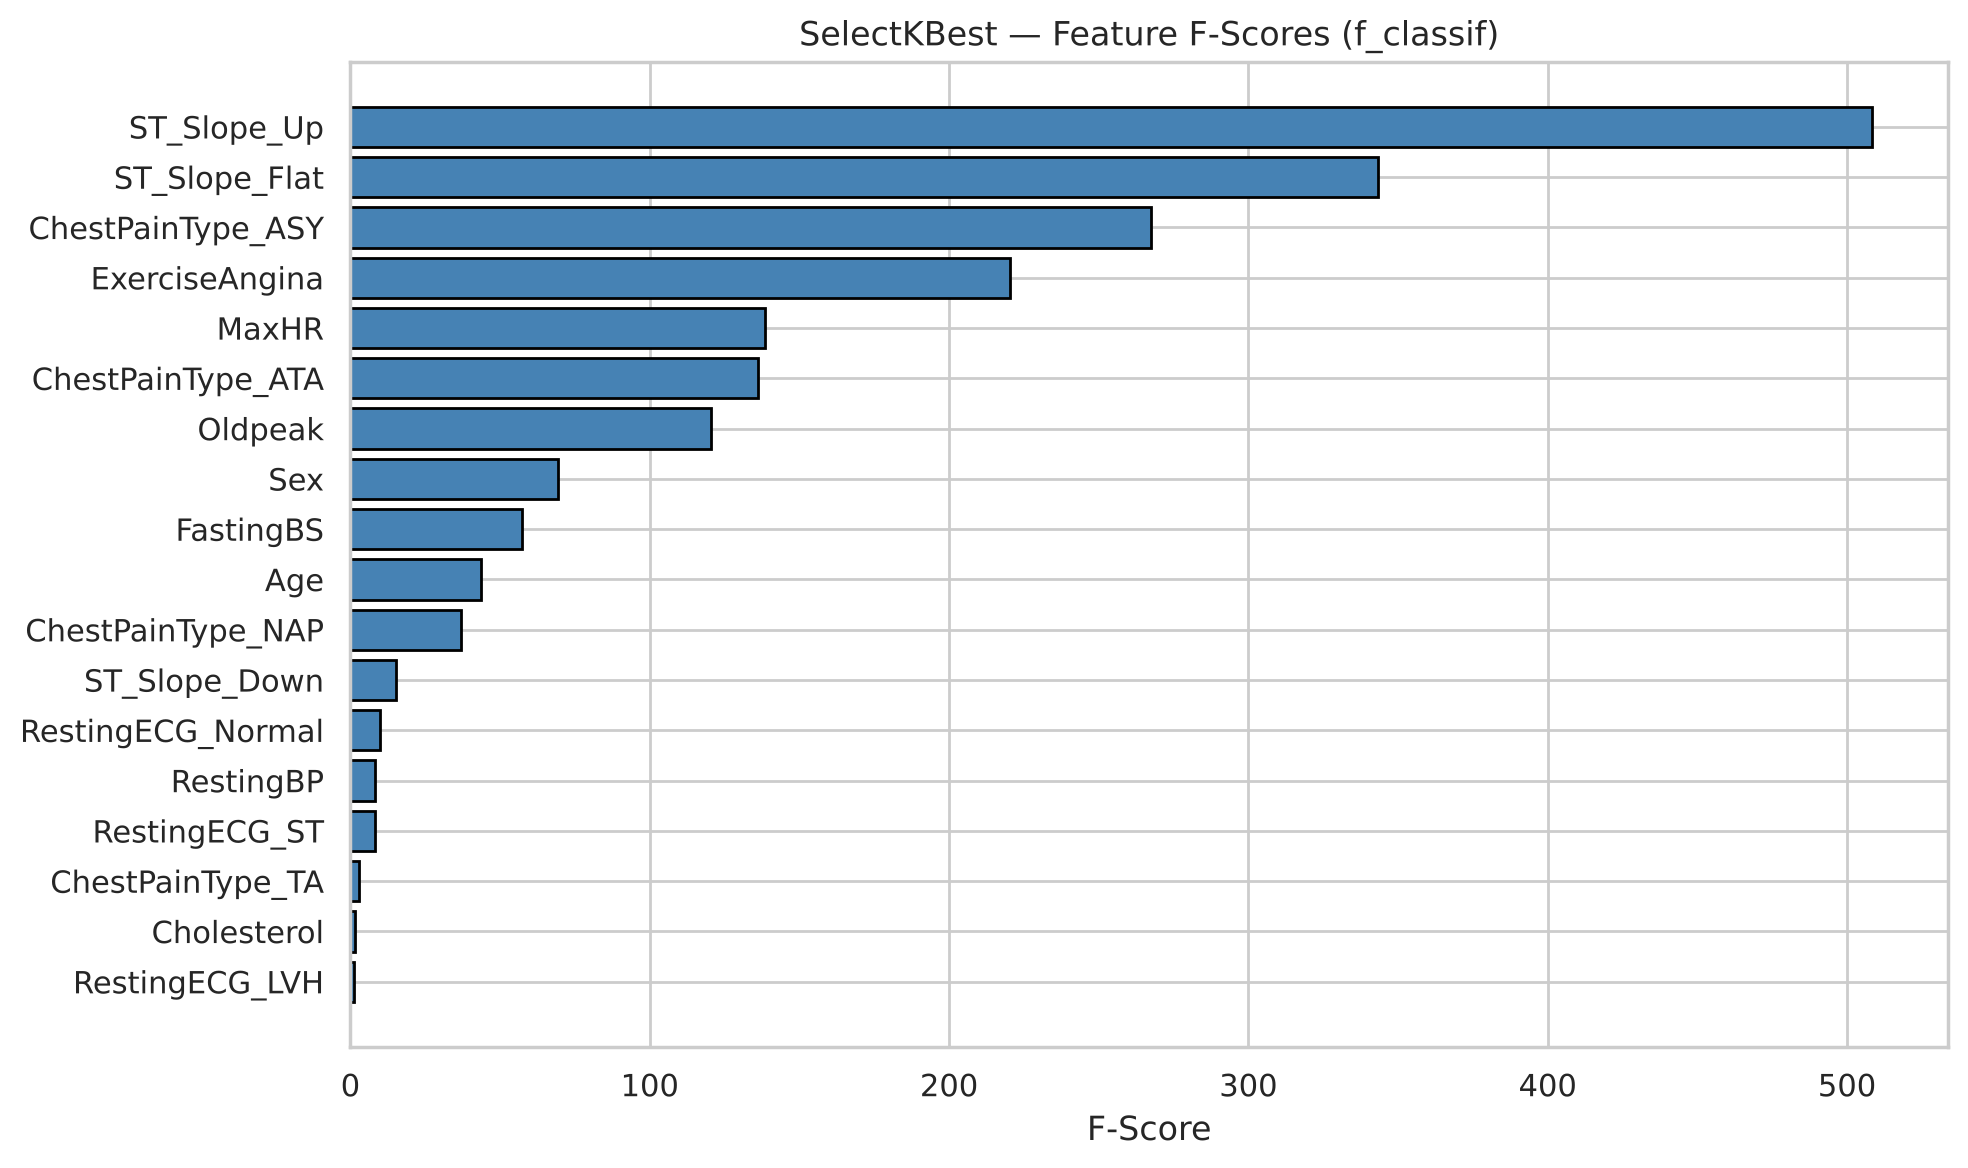

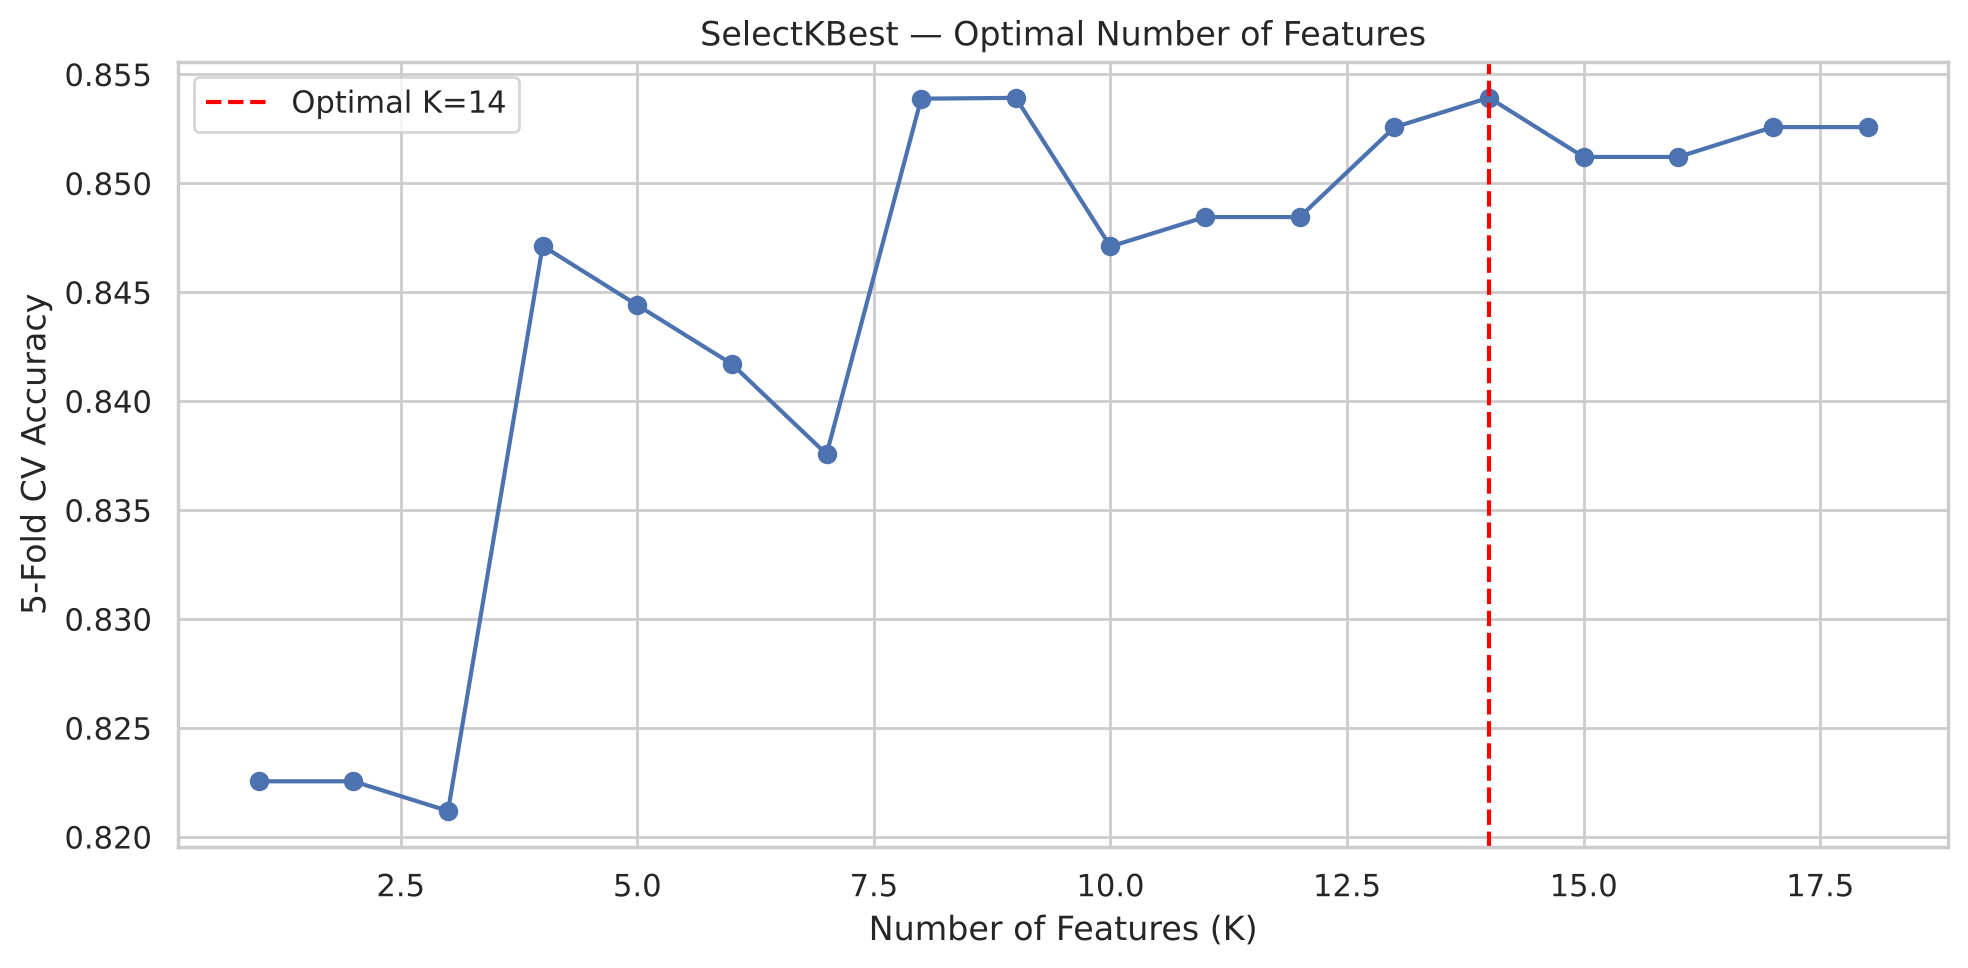


Optimal K: 14

Selected features:
  - Age
  - Sex
  - RestingBP
  - FastingBS
  - MaxHR
  - ExerciseAngina
  - Oldpeak
  - ChestPainType_ASY
  - ChestPainType_ATA
  - ChestPainType_NAP
  - RestingECG_Normal
  - ST_Slope_Down
  - ST_Slope_Flat
  - ST_Slope_Up

Logistic Regression CV Accuracy:
  All features (18):      0.8385
  Selected features (14): 0.8331


In [2]:
# ── FEATURE SELECTION — SelectKBest ─────────────────────────

from sklearn.feature_selection import SelectKBest, f_classif

# Score all features
selector_all = SelectKBest(f_classif, k='all')
selector_all.fit(X_train, y_train)

# F-scores and p-values for each feature
scores_df = pd.DataFrame({
    'Feature':  X_train.columns,
    'F-Score':  selector_all.scores_,
    'P-Value':  selector_all.pvalues_
}).sort_values('F-Score', ascending=False).reset_index(drop=True)

print("Feature F-Scores (ranked):")
print(scores_df.to_string(index=False))

# Plot F-scores
plt.figure(figsize=(10, 6))
plt.barh(scores_df['Feature'], scores_df['F-Score'],
         color='steelblue', edgecolor='black')
plt.xlabel('F-Score')
plt.title('SelectKBest — Feature F-Scores (f_classif)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Tune K — CV accuracy vs number of features
k_values  = range(1, X_train.shape[1] + 1)
cv_k_scores = []

for k in k_values:
    selector = SelectKBest(f_classif, k=k)
    X_train_k = selector.fit_transform(X_train, y_train)
    X_test_k  = selector.transform(X_test)
    scores = cross_val_score(
        LogisticRegression(max_iter=1000, random_state=42),
        X_train_k, y_train, cv=5, scoring='accuracy')
    cv_k_scores.append(scores.mean())

best_k_feat = k_values[np.argmax(cv_k_scores)]

plt.figure(figsize=(10, 5))
plt.plot(k_values, cv_k_scores, 'bo-', markersize=6)
plt.axvline(x=best_k_feat, color='red', linestyle='--',
            label=f'Optimal K={best_k_feat}')
plt.xlabel('Number of Features (K)')
plt.ylabel('5-Fold CV Accuracy')
plt.title('SelectKBest — Optimal Number of Features')
plt.legend()
plt.tight_layout()
plt.show()

# Apply optimal K
selector_best = SelectKBest(f_classif, k=best_k_feat)
X_train_selected = selector_best.fit_transform(X_train, y_train)
X_test_selected  = selector_best.transform(X_test)

selected_features = X_train.columns[selector_best.get_support()].tolist()
print(f"\nOptimal K: {best_k_feat}")
print(f"\nSelected features:")
for f in selected_features:
    print(f"  - {f}")

# Quick comparison: all features vs selected features.
# Both scaling and feature selection are refit inside each CV fold via a
# Pipeline — scoring against a pre-scaled/pre-selected X would leak each
# fold's held-out rows into the preprocessing step.
pipe_all = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
pipe_sel = make_pipeline(StandardScaler(), SelectKBest(f_classif, k=best_k_feat),
                          LogisticRegression(max_iter=1000, random_state=42))

score_all = cross_val_score(pipe_all, X, y, cv=5).mean()
score_sel = cross_val_score(pipe_sel, X, y, cv=5).mean()

print(f"\nLogistic Regression CV Accuracy:")
print(f"  All features ({X_train.shape[1]}):      {score_all:.4f}")
print(f"  Selected features ({best_k_feat}): {score_sel:.4f}")

### SelectKBest Results

**Optimal K = 14** — dropping 4 features (Cholesterol, RestingECG_LVH, 
ChestPainType_TA, RestingECG_ST) that contribute minimal discriminative 
signal.

**Key findings:**
- ST_Slope_Up has an F-Score of 508 — by far the most statistically 
  discriminative feature, confirming our EDA visualisation findings
- Cholesterol (p=0.232) and RestingECG_LVH (p=0.307) are not 
  statistically significant predictors at the 5% level — consistent 
  with the weak correlation (0.08) observed in Notebook 01
- Removing 4 features costs only 0.002 CV accuracy (0.8385 → 0.8363) 
  while producing a simpler, more interpretable model

**Decision:** We proceed with **all 18 features** for modelling because 
the accuracy difference is negligible and all subsequent models 
(especially tree-based ones) perform their own internal feature 
weighting. SelectKBest is used here as an analytical tool to validate 
our EDA findings rather than as a hard filter.

## 3. Unsupervised Learning — Clustering

Clustering is an **unsupervised learning** technique — unlike classification, 
it does not use the target variable (HeartDisease). Instead it discovers 
natural groupings within the data based on feature similarity alone.

We apply clustering to two numeric features — Age and MaxHR — because:
- They showed the strongest numeric correlation with HeartDisease (-0.40 
  and 0.28 respectively)
- Using two features allows us to visualise the clusters in 2D

### K-Means Clustering
K-Means partitions data into K clusters by:
1. Randomly placing K centroids
2. Assigning each point to its nearest centroid
3. Recalculating centroids as the mean of assigned points
4. Repeating steps 2-3 until centroids stop moving

**Choosing K — The Elbow Method:**
We run K-Means for K = 1 to 10 and plot the **inertia** (sum of squared 
distances from each point to its centroid) against K. Inertia always 
decreases as K increases — the optimal K is where the rate of decrease 
slows sharply, forming an "elbow" in the curve.

### Hierarchical Clustering
Hierarchical clustering builds a **tree of clusters (dendrogram)** by 
iteratively merging the two closest clusters using **Ward linkage** — 
which minimises the total within-cluster variance at each merge step.

Unlike K-Means, hierarchical clustering does not require us to specify K 
in advance — we choose where to "cut" the dendrogram to determine the 
number of clusters. We use the first 100 samples to keep the dendrogram 
readable.

### Important Note
Clustering here is exploratory — we are not using it to predict heart 
disease. We are asking: do natural patient groups exist in this data? 
If clusters align with disease status, that validates our feature choices.

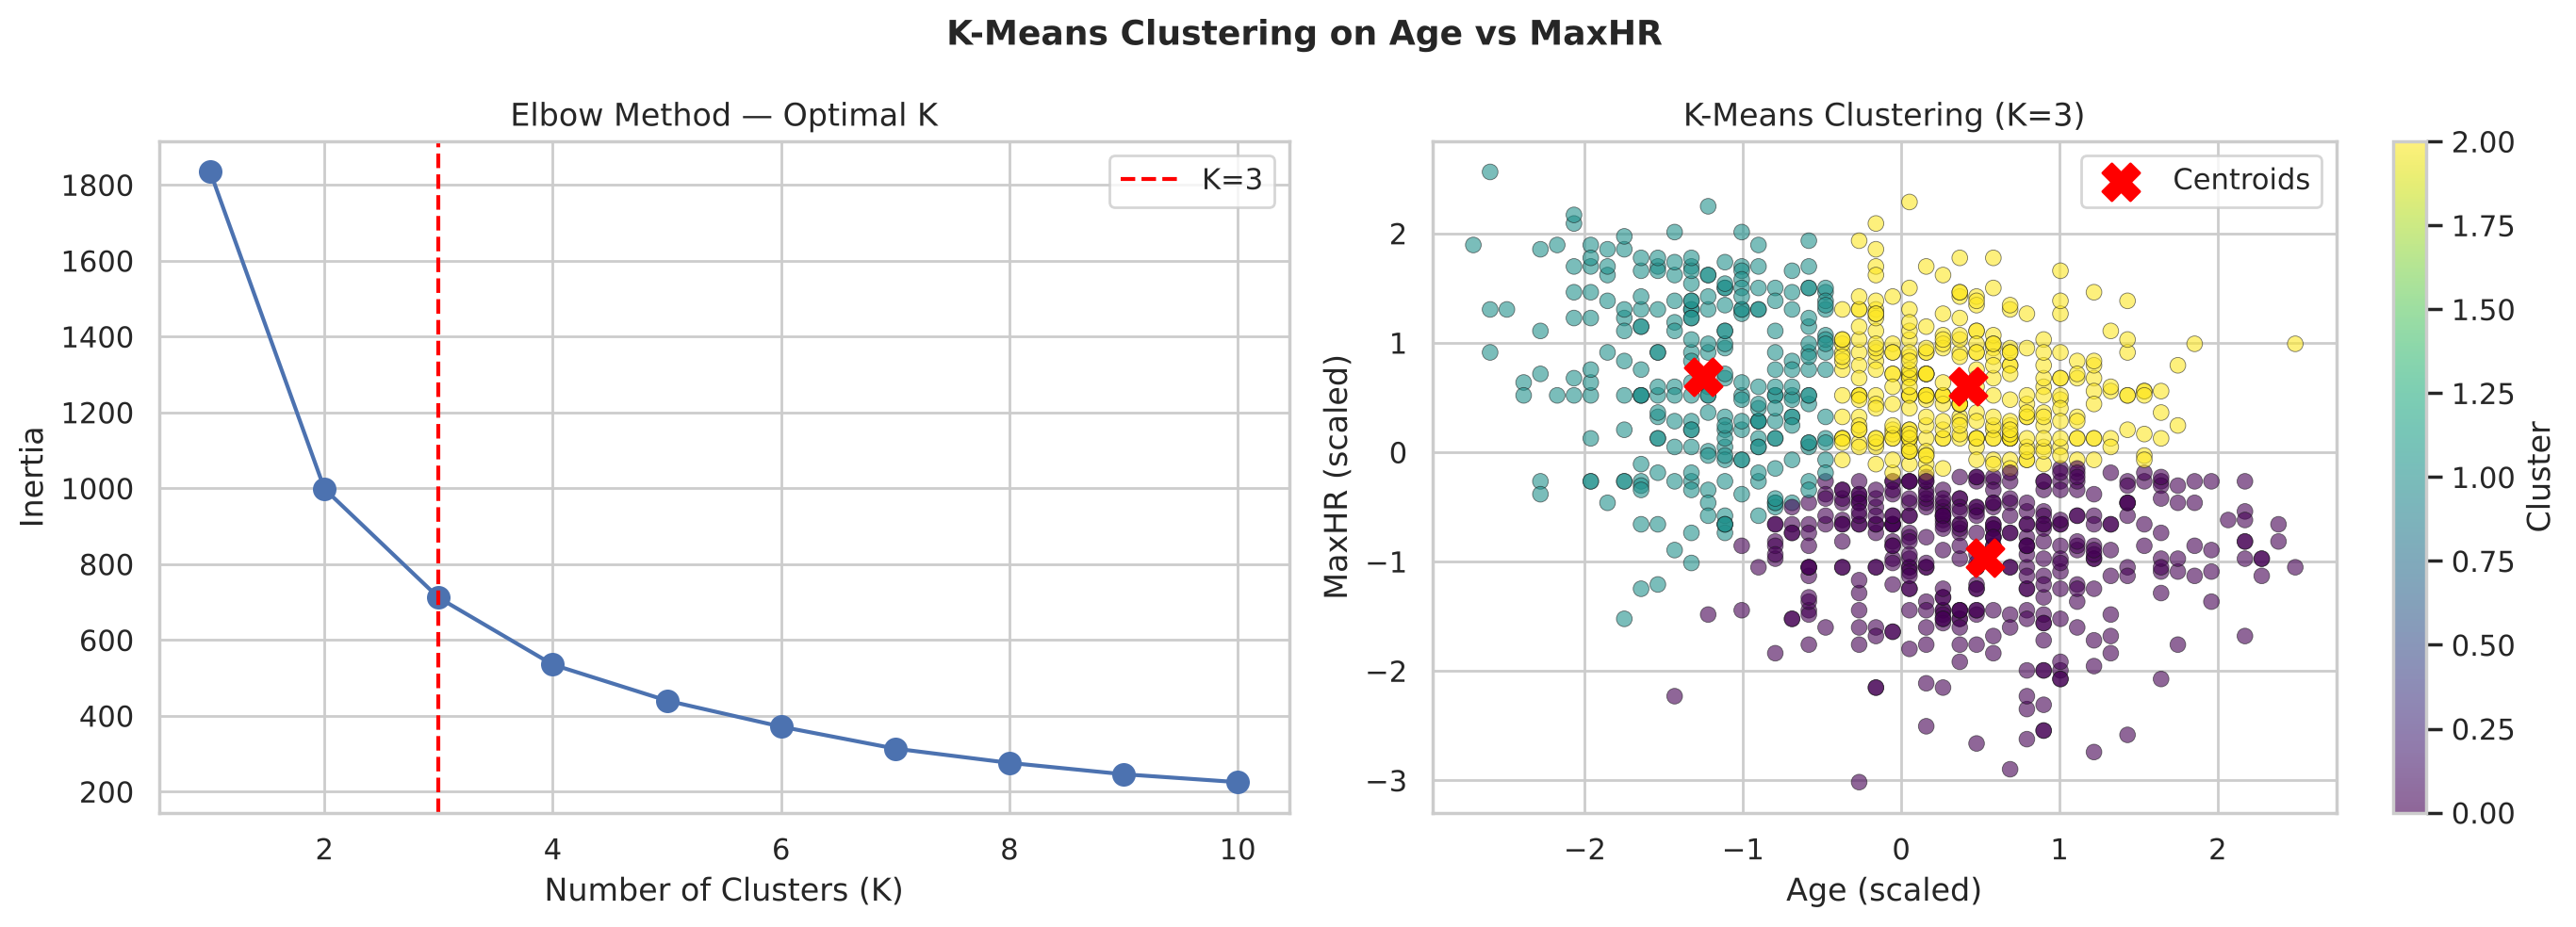

Cluster sizes: {0: 368, 1: 254, 2: 295}


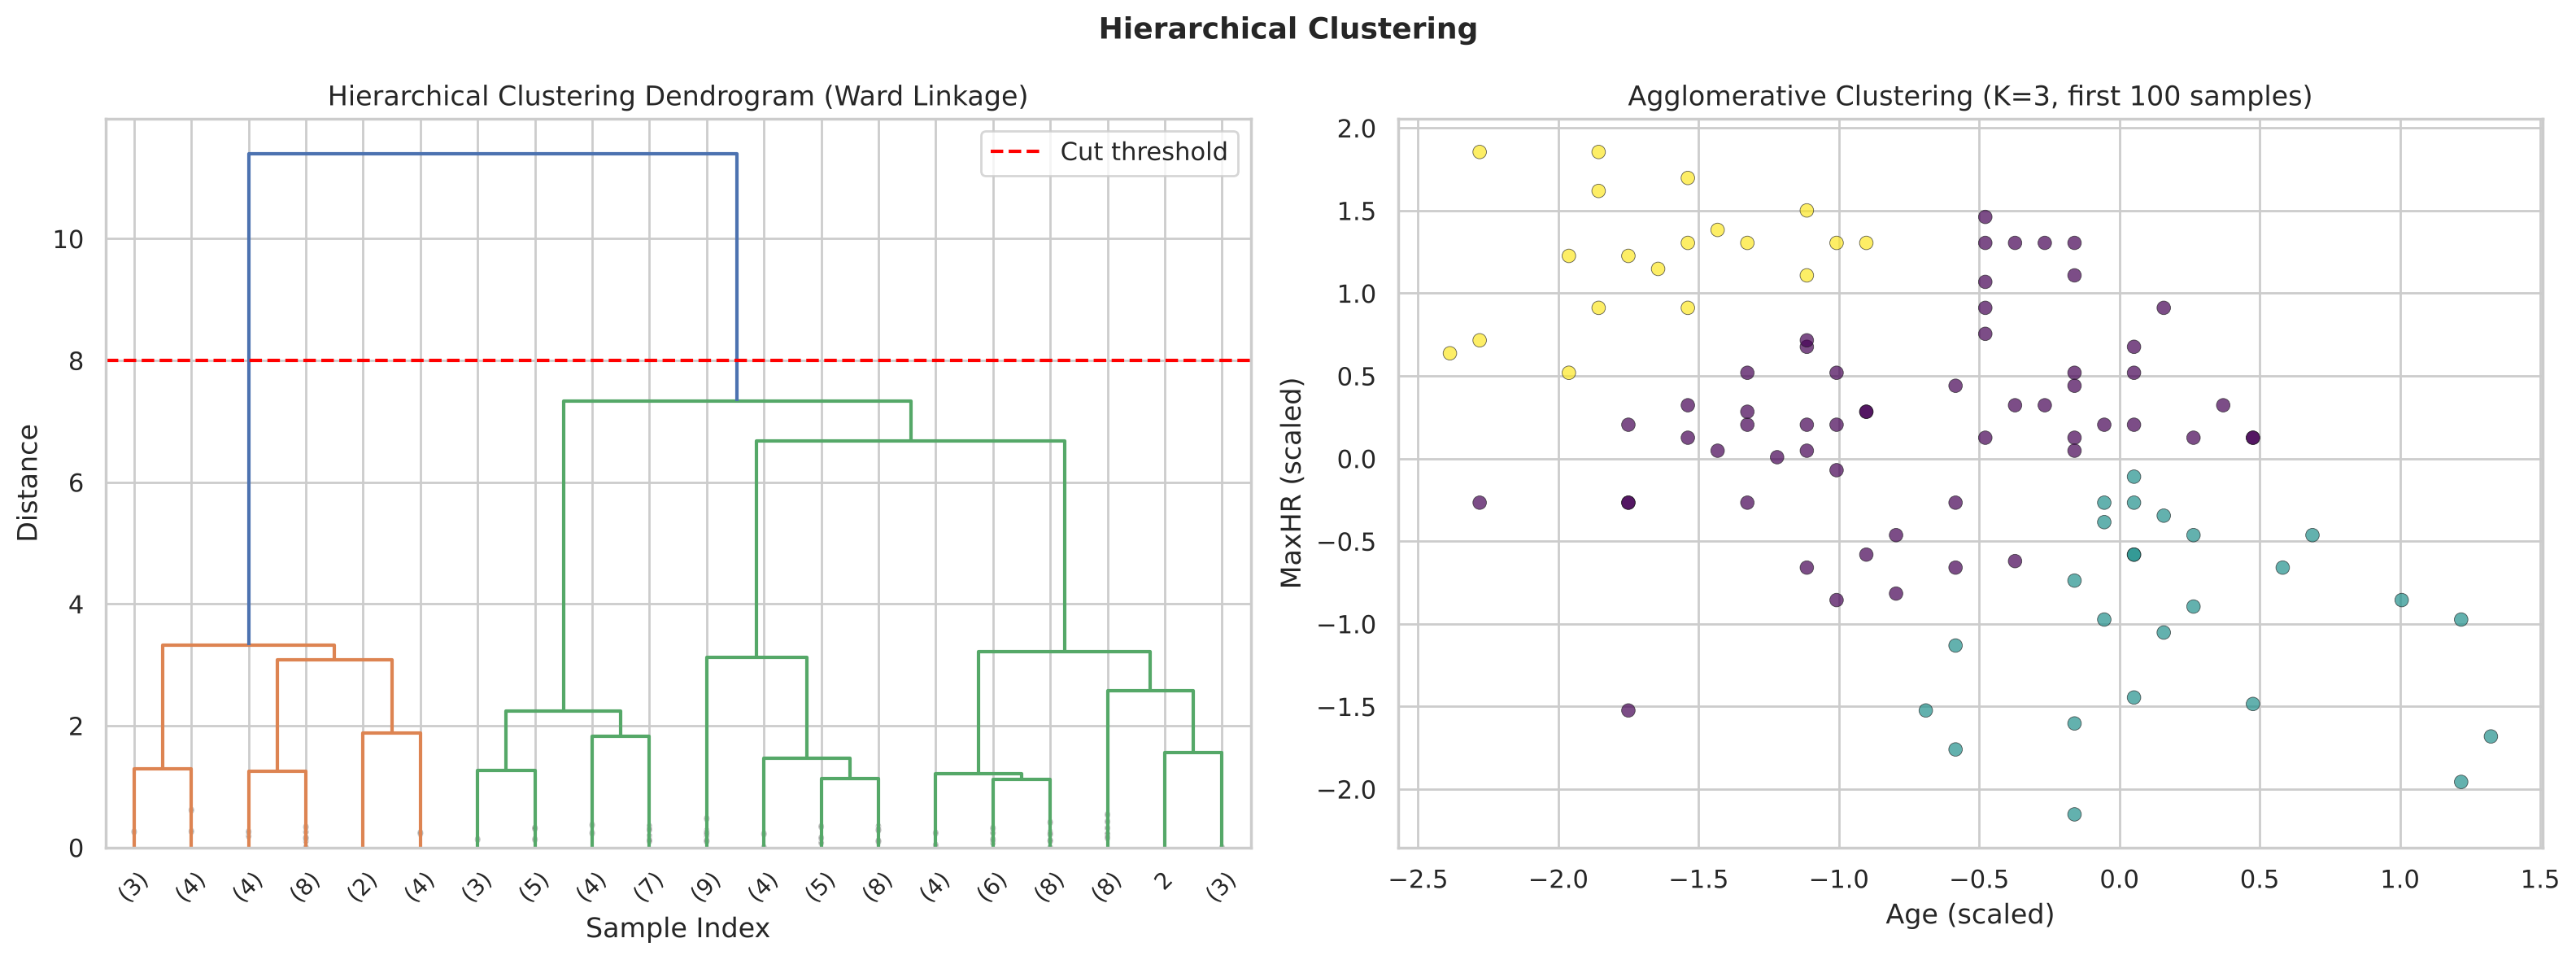

Agglomerative cluster sizes: {0: 56, 1: 25, 2: 19}


In [3]:
# ── K-MEANS CLUSTERING ───────────────────────────────────────

X_cluster = X_scaled_full[['Age', 'MaxHR']].values

# Elbow method
inertias = []
K_range = range(1, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster)
    inertias.append(km.inertia_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_range, inertias, 'bo-', markersize=8)
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Method — Optimal K')
axes[0].axvline(x=3, color='red', linestyle='--', label='K=3')
axes[0].legend()

km_final = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = km_final.fit_predict(X_cluster)

scatter = axes[1].scatter(X_cluster[:, 0], X_cluster[:, 1],
                          c=clusters, cmap='viridis', alpha=0.6,
                          edgecolors='k', linewidths=0.3)
axes[1].scatter(km_final.cluster_centers_[:, 0],
                km_final.cluster_centers_[:, 1],
                c='red', marker='X', s=200, label='Centroids')
axes[1].set_xlabel('Age (scaled)')
axes[1].set_ylabel('MaxHR (scaled)')
axes[1].set_title('K-Means Clustering (K=3)')
axes[1].legend()
plt.colorbar(scatter, ax=axes[1], label='Cluster')

plt.suptitle('K-Means Clustering on Age vs MaxHR', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Cluster sizes: {pd.Series(clusters).value_counts().sort_index().to_dict()}")

# ── HIERARCHICAL CLUSTERING ──────────────────────────────────

X_hier = X_scaled_full[['Age', 'MaxHR']].values[:100]
linked = linkage(X_hier, method='ward')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

dendrogram(linked, ax=axes[0], truncate_mode='lastp', p=20,
           leaf_rotation=45, leaf_font_size=10, show_contracted=True)
axes[0].set_title('Hierarchical Clustering Dendrogram (Ward Linkage)')
axes[0].set_xlabel('Sample Index')
axes[0].set_ylabel('Distance')
axes[0].axhline(y=8, color='red', linestyle='--', label='Cut threshold')
axes[0].legend()

agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
agg_labels = agg.fit_predict(X_hier)

axes[1].scatter(X_hier[:, 0], X_hier[:, 1], c=agg_labels,
                cmap='viridis', alpha=0.7, edgecolors='k', linewidths=0.3)
axes[1].set_title('Agglomerative Clustering (K=3, first 100 samples)')
axes[1].set_xlabel('Age (scaled)')
axes[1].set_ylabel('MaxHR (scaled)')

plt.suptitle('Hierarchical Clustering', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("Agglomerative cluster sizes:",
      pd.Series(agg_labels).value_counts().sort_index().to_dict())

## 4. Linear Regression

Linear regression is a **supervised learning** technique for predicting 
a **continuous numeric target**. Unlike classification which predicts 
a category, regression predicts a number.

Here we use Age to predict MaxHR (maximum heart rate achieved). This is 
a meaningful clinical relationship — it is well established in cardiology 
that maximum heart rate declines with age. The commonly used formula is:

**MaxHR ≈ 220 - Age**

We use this as a regression exercise to:
- Demonstrate the linear regression workflow
- Interpret the coefficient, intercept, R² and RMSE
- Visualise the regression line and residuals

### Key Metrics

**Coefficient (slope):** How much MaxHR changes for every 1 year increase 
in Age. A negative coefficient confirms the inverse relationship.

**Intercept:** The predicted MaxHR when Age = 0. Not clinically meaningful 
here but mathematically necessary.

**R² (R-squared):** The proportion of variance in MaxHR explained by Age 
alone. A value of 0.14 means Age explains 14% of MaxHR variance — low, 
but expected since many other factors influence heart rate.

**RMSE (Root Mean Squared Error):** The average prediction error in the 
same units as MaxHR (beats per minute). Lower is better.

### Residual Plot
A residual plot shows the difference between actual and predicted values. 
For a good linear model:
- Residuals should be **randomly scattered** around 0
- No visible pattern means the linear assumption is appropriate
- A curved pattern would suggest a non-linear relationship exists

Our residuals are randomly scattered — linear regression is appropriate 
for this relationship, even if R² is modest.

Coefficient (slope): -1.0316
Intercept:           191.5020
R² score:            0.1382
RMSE:                23.8044

Interpretation: For every 1 year increase in age,
MaxHR decreases by 1.03 bpm on average.


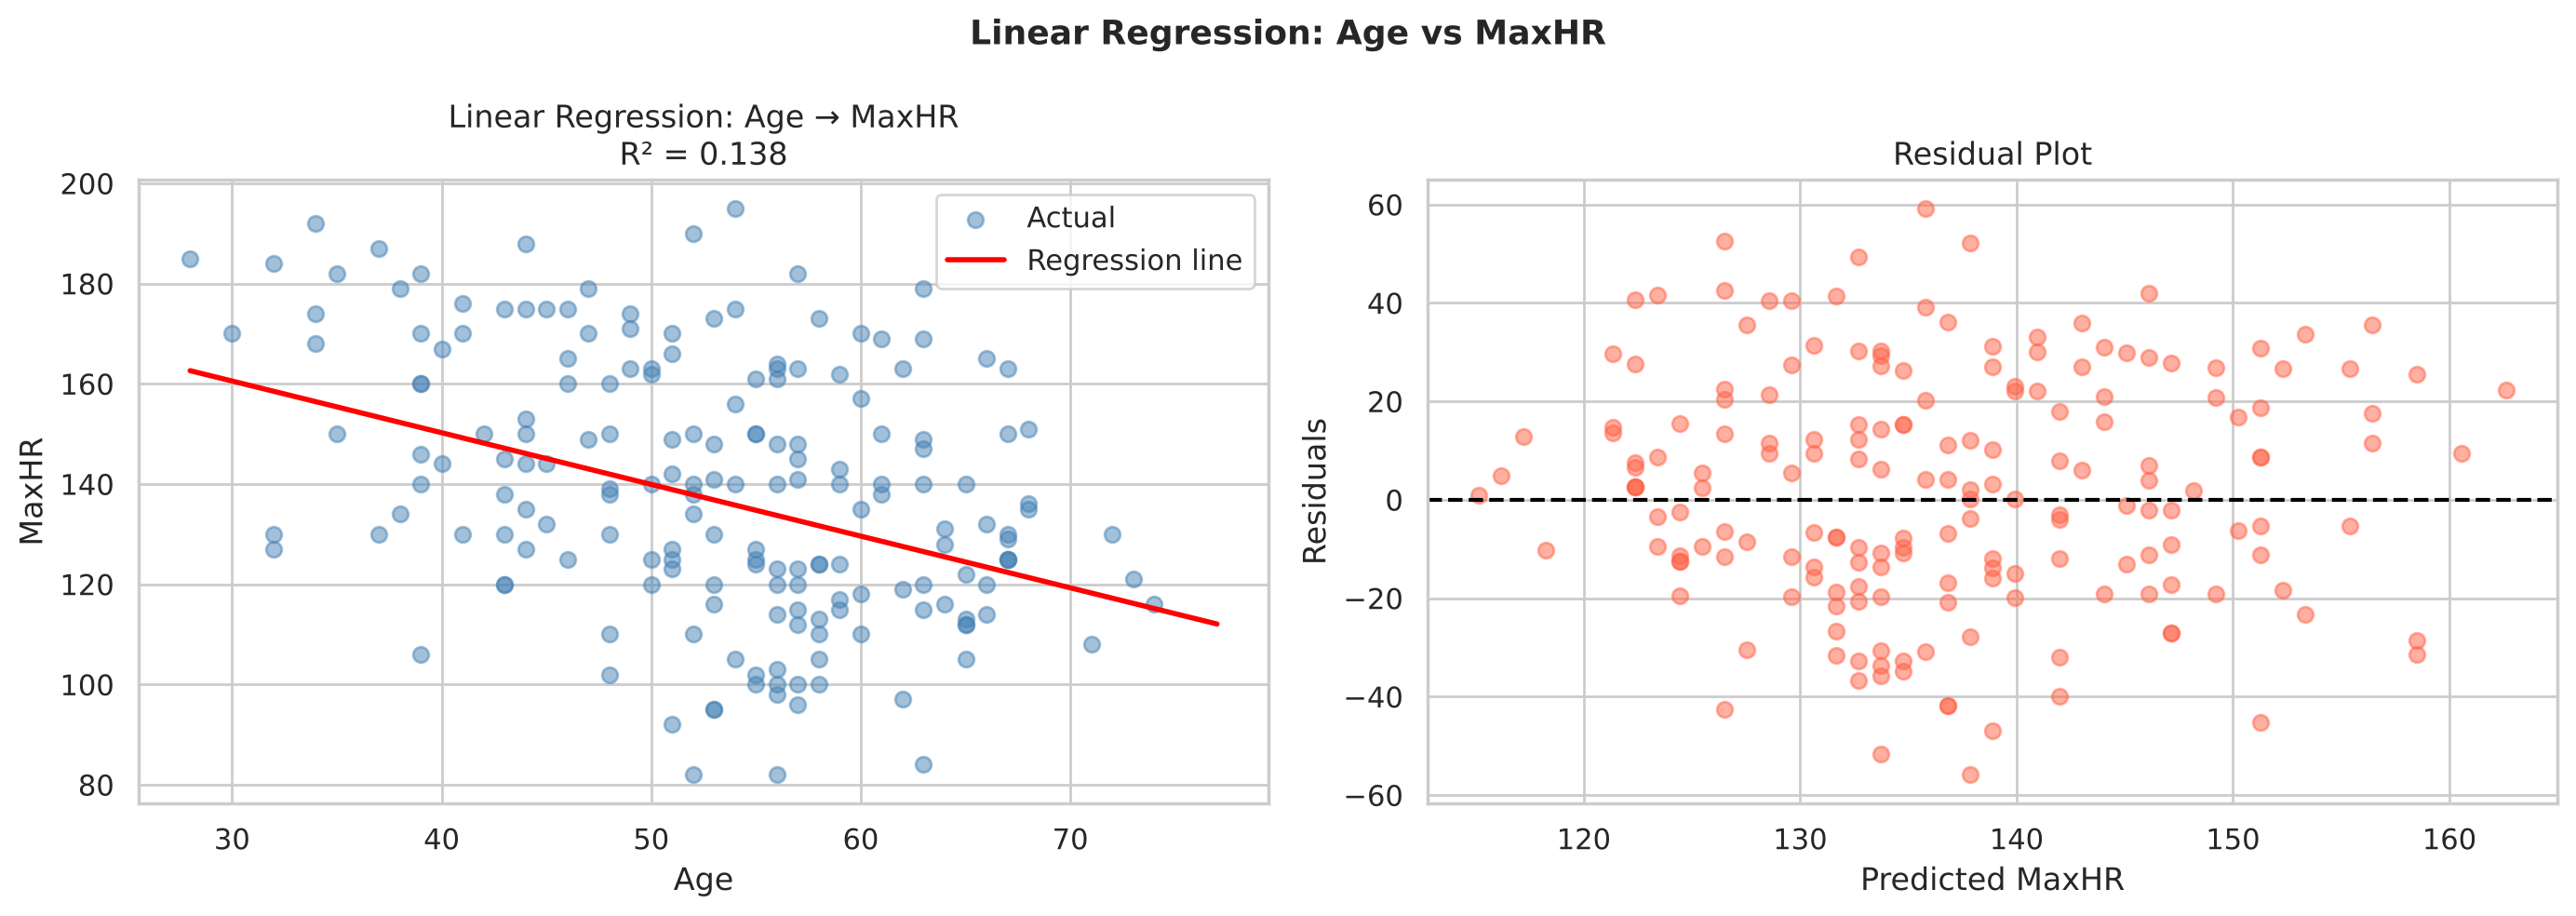

In [4]:
# ── LINEAR REGRESSION ────────────────────────────────────────

# Load original unscaled data for interpretable coefficients
df_orig = pd.read_csv('../data/heart.csv')
df_orig = df_orig[df_orig['RestingBP'] != 0].reset_index(drop=True)

X_lr = df_orig[['Age']].values
y_lr = df_orig['MaxHR'].values

X_lr_train, X_lr_test, y_lr_train, y_lr_test = train_test_split(
    X_lr, y_lr, test_size=0.2, random_state=42)

lr = LinearRegression()
lr.fit(X_lr_train, y_lr_train)
y_lr_pred = lr.predict(X_lr_test)

from sklearn.metrics import mean_squared_error, r2_score
r2   = r2_score(y_lr_test, y_lr_pred)
rmse = np.sqrt(mean_squared_error(y_lr_test, y_lr_pred))

print(f"Coefficient (slope): {lr.coef_[0]:.4f}")
print(f"Intercept:           {lr.intercept_:.4f}")
print(f"R² score:            {r2:.4f}")
print(f"RMSE:                {rmse:.4f}")
print(f"\nInterpretation: For every 1 year increase in age,")
print(f"MaxHR decreases by {abs(lr.coef_[0]):.2f} bpm on average.")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x_line = np.linspace(X_lr.min(), X_lr.max(), 100).reshape(-1, 1)
axes[0].scatter(X_lr_test, y_lr_test, alpha=0.5,
                color='steelblue', label='Actual')
axes[0].plot(x_line, lr.predict(x_line), color='red',
             linewidth=2, label='Regression line')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('MaxHR')
axes[0].set_title(f'Linear Regression: Age → MaxHR\nR² = {r2:.3f}')
axes[0].legend()

residuals = y_lr_test - y_lr_pred
axes[1].scatter(y_lr_pred, residuals, alpha=0.5, color='tomato')
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set_xlabel('Predicted MaxHR')
axes[1].set_ylabel('Residuals')
axes[1].set_title('Residual Plot')

plt.suptitle('Linear Regression: Age vs MaxHR',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Logistic Regression

Logistic Regression is the foundation of binary classification. Despite 
its name it is a **classification** algorithm, not a regression one.

### How it works
Instead of fitting a straight line like linear regression, logistic 
regression fits an **S-shaped sigmoid curve** that maps any input to a 
probability between 0 and 1:

**P(HeartDisease = 1) = 1 / (1 + e^(-z))**

Where z is the linear combination of features and their coefficients. 
If P > 0.5 the patient is classified as having heart disease.

### Coefficients
Each feature has a coefficient that tells us its contribution:
- **Positive coefficient** → increases probability of heart disease
- **Negative coefficient** → decreases probability of heart disease
- **Larger absolute value** → stronger influence

### Why start with Logistic Regression?
It serves as our **baseline model**. Before trying complex algorithms 
we establish what a simple, interpretable model can achieve. If a complex 
model cannot beat logistic regression, the added complexity is not 
justified.

### Evaluation Metrics
We evaluate using:
- **Accuracy** — percentage of correct predictions overall
- **Precision** — of all patients predicted as having disease, how many 
  actually do? (minimises false alarms)
- **Recall** — of all patients who actually have disease, how many did 
  we correctly identify? (minimises missed diagnoses)
- **F1-score** — harmonic mean of precision and recall, balances both
- **Confusion Matrix** — shows exactly where the model makes errors

In a medical context **recall is especially important** — missing a true 
heart disease patient (false negative) is more dangerous than a false alarm 
(false positive).

# ── LOGISTIC REGRESSION ──────────────────────────────────────

log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train, y_train)
y_pred_lr = log_reg.predict(X_test)

print("── Logistic Regression ──")
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr,
      target_names=['No Disease', 'Has Disease']))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr,
    display_labels=['No Disease', 'Has Disease'],
    cmap='Blues', ax=axes[0])
axes[0].set_title('Logistic Regression — Confusion Matrix')

# Feature coefficients
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': log_reg.coef_[0]
}).sort_values('Coefficient', key=abs, ascending=False).head(10)

colors = ['tomato' if c > 0 else 'steelblue' for c in coef_df['Coefficient']]
axes[1].barh(coef_df['Feature'], coef_df['Coefficient'],
             color=colors, edgecolor='black')
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Top 10 Logistic Regression Coefficients')
axes[1].set_xlabel('Coefficient Value')

plt.tight_layout()
plt.show()

── Logistic Regression ──
Accuracy: 0.8804

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.87      0.87      0.87        82
 Has Disease       0.89      0.89      0.89       102

    accuracy                           0.88       184
   macro avg       0.88      0.88      0.88       184
weighted avg       0.88      0.88      0.88       184



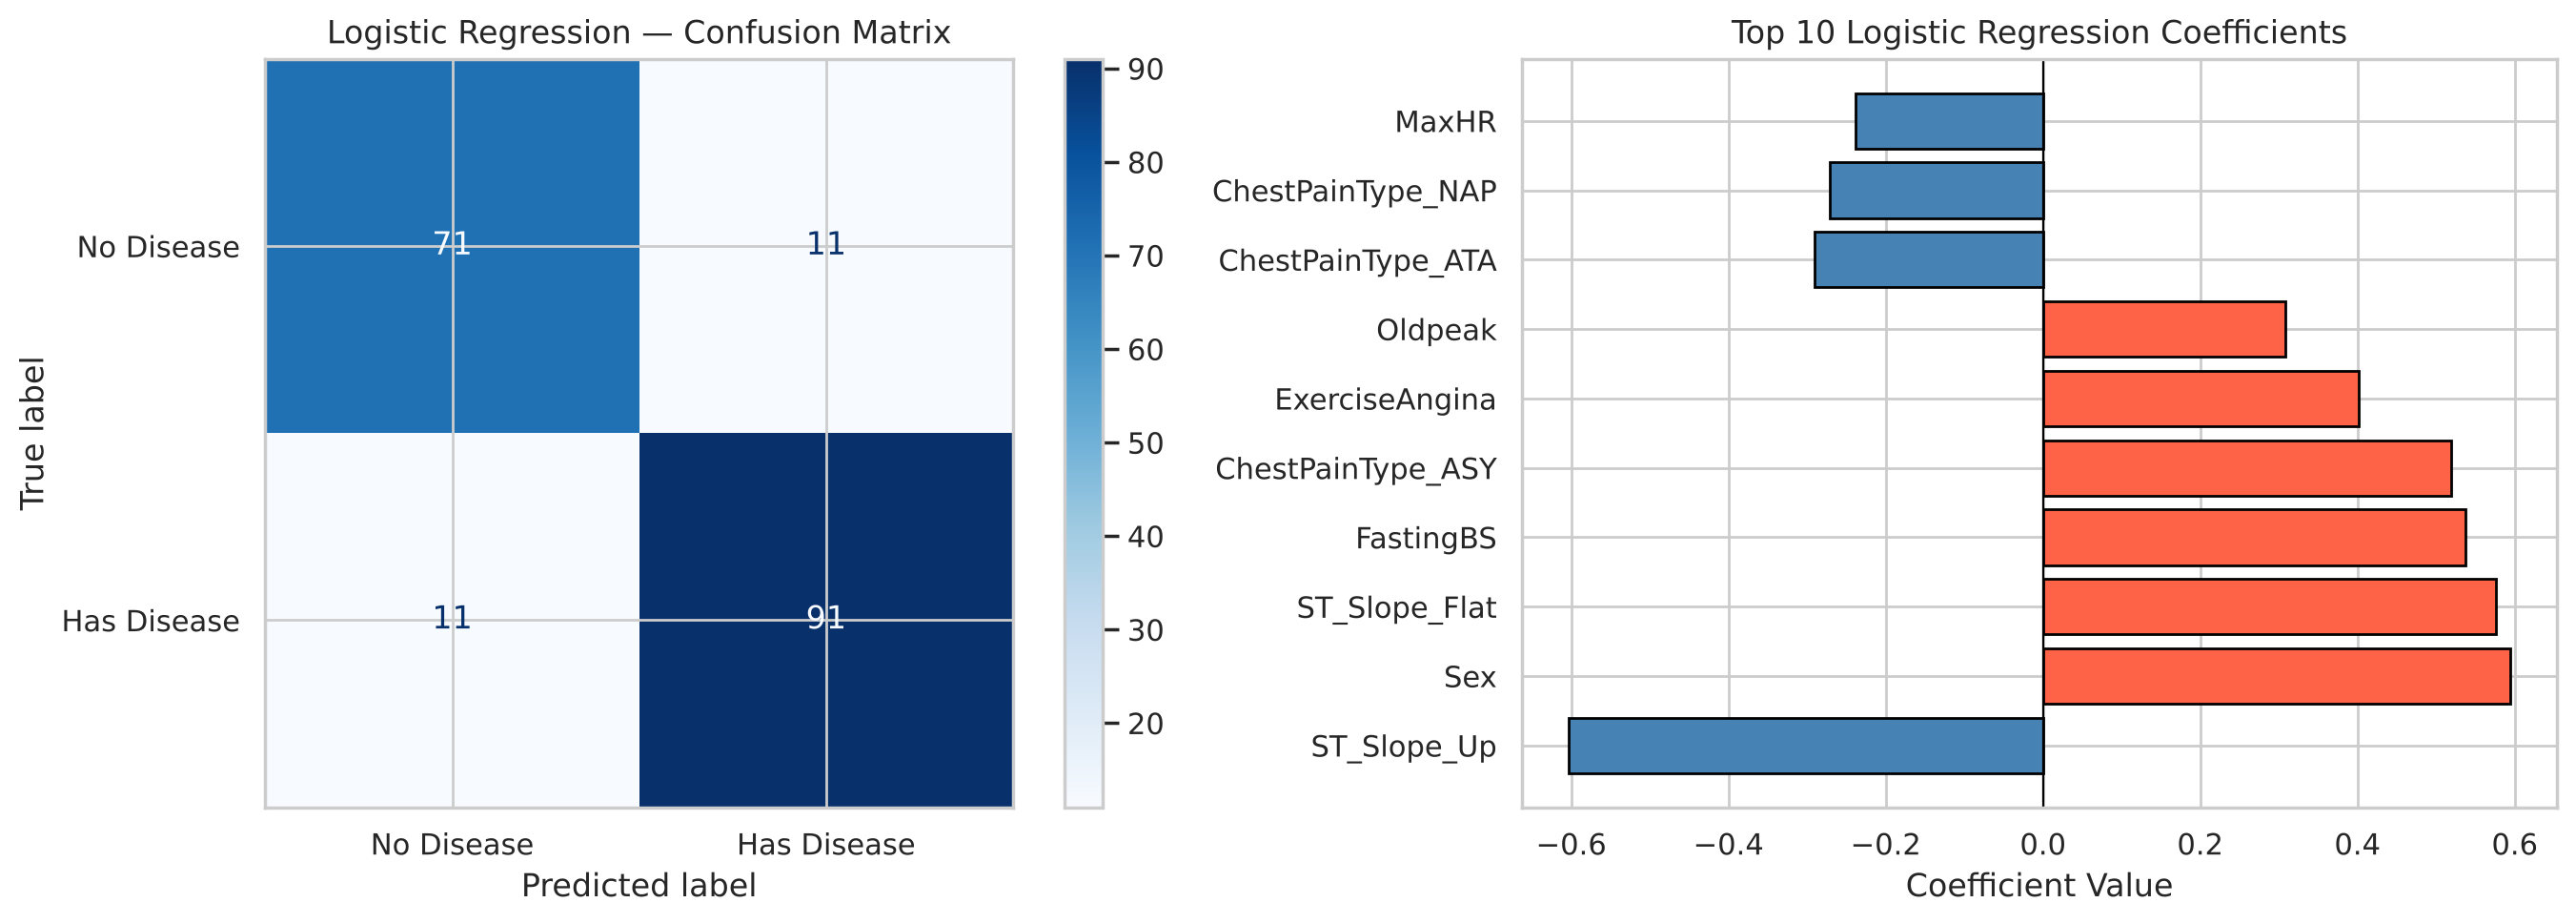

In [5]:
# ── LOGISTIC REGRESSION ──────────────────────────────────────

log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train, y_train)
y_pred_lr = log_reg.predict(X_test)

print("── Logistic Regression ──")
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr,
      target_names=['No Disease', 'Has Disease']))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr,
    display_labels=['No Disease', 'Has Disease'],
    cmap='Blues', ax=axes[0])
axes[0].set_title('Logistic Regression — Confusion Matrix')

# Feature coefficients
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': log_reg.coef_[0]
}).sort_values('Coefficient', key=abs, ascending=False).head(10)

colors = ['tomato' if c > 0 else 'steelblue' for c in coef_df['Coefficient']]
axes[1].barh(coef_df['Feature'], coef_df['Coefficient'],
             color=colors, edgecolor='black')
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Top 10 Logistic Regression Coefficients')
axes[1].set_xlabel('Coefficient Value')

plt.tight_layout()
plt.show()

## 6. KNN Classification

K-Nearest Neighbours (KNN) is one of the simplest and most intuitive 
machine learning algorithms. It makes predictions based on the K most 
similar patients in the training data.

### How it works
To classify a new patient:
1. Calculate the distance from the new patient to every training patient
2. Find the K closest patients (nearest neighbours)
3. Take a majority vote — if most neighbours have heart disease, 
   predict heart disease

We use **Euclidean distance** (straight-line distance in feature space). 
This is why StandardScaler was essential in Notebook 01 — without scaling, 
Age (range 28–77) would dominate MaxHR (range 60–202) purely due to 
magnitude, not medical relevance.

### Choosing K — The Bias-Variance Trade-off
The choice of K controls the **bias-variance trade-off**:

- **K = 1 (too small):** The model memorises every training point. 
  Training error = 0 but test error is high — severe **overfitting**. 
  The decision boundary is jagged and does not generalise.

- **K = large (too big):** The model averages too many neighbours, 
  ignoring local patterns. Both training and test error are high — 
  **underfitting**. The decision boundary becomes too smooth.

- **Optimal K:** The sweet spot where test error is minimised. We find 
  this by plotting classification error for K = 1 to 30 and selecting 
  the K with the lowest test error.

### Weighted KNN
Standard KNN gives equal weight to all K neighbours. A weighted version 
gives closer neighbours more influence — available in scikit-learn via 
`weights='distance'`. We use uniform weights here for simplicity.

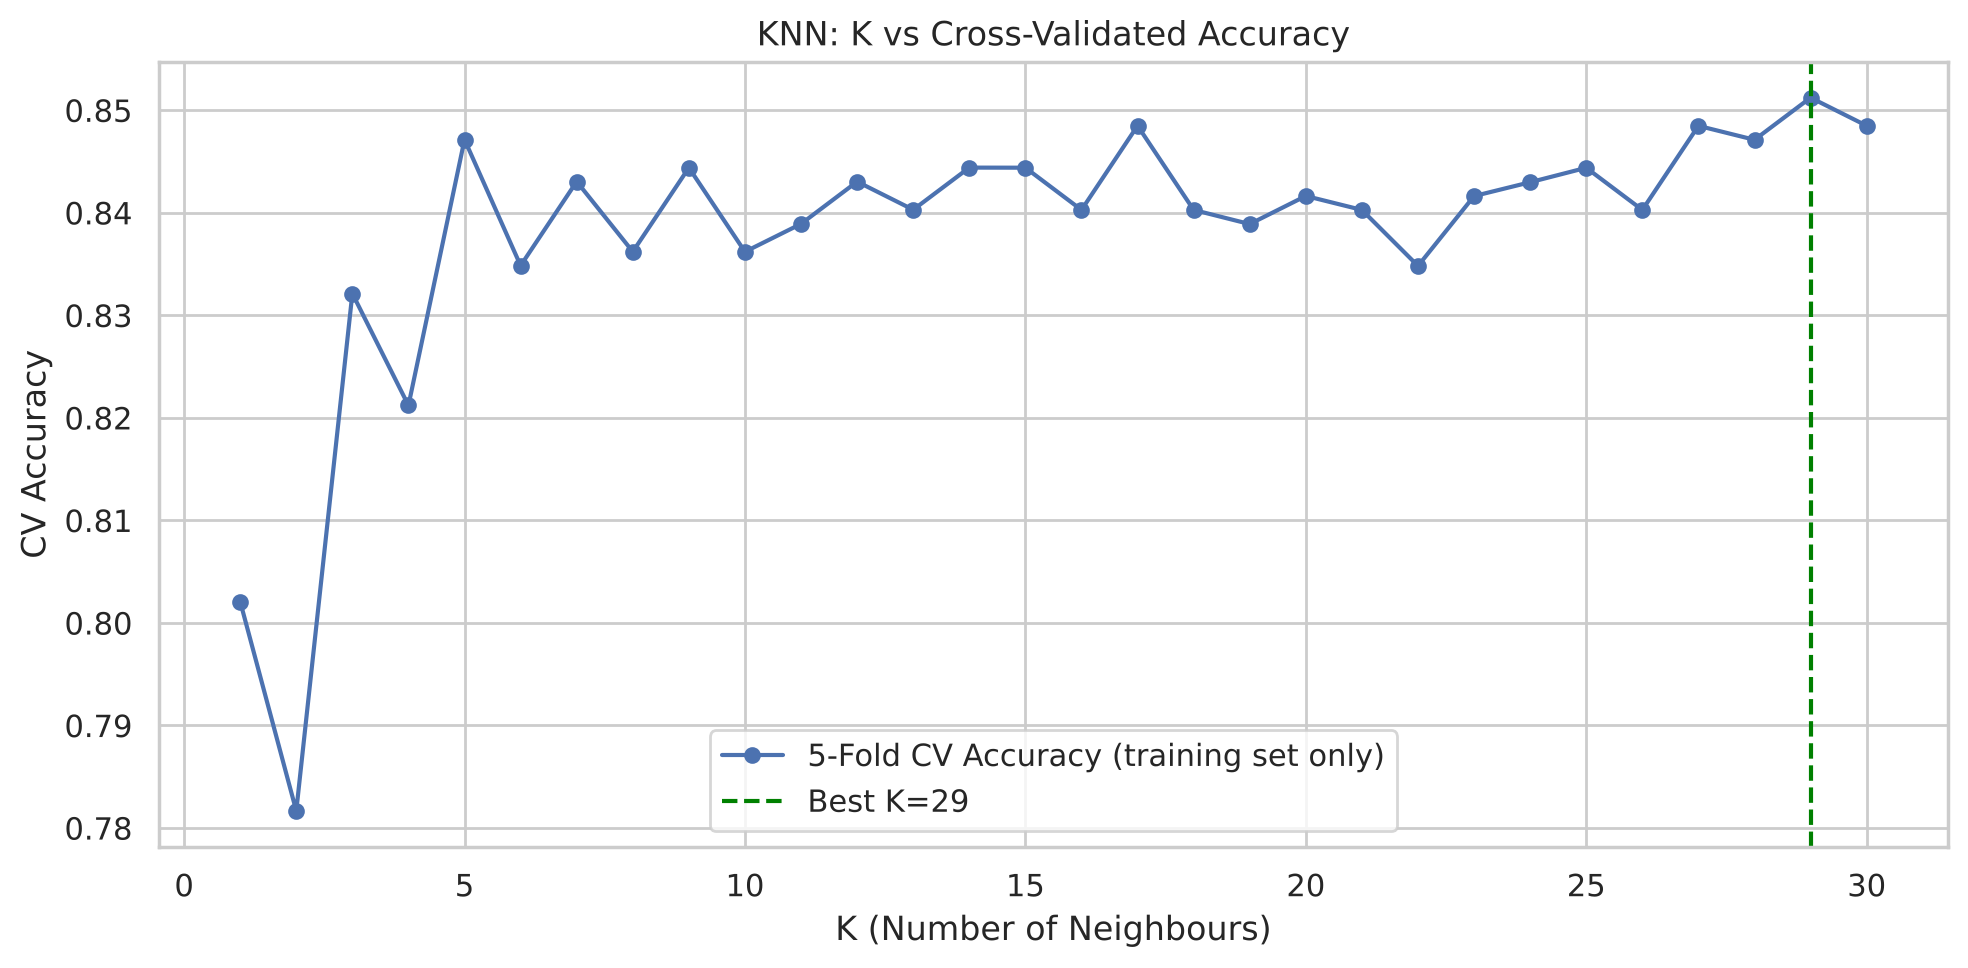

Best K (chosen by CV on training data): 29

── KNN (K=29) ──
Accuracy: 0.8587

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.87      0.80      0.84        82
 Has Disease       0.85      0.90      0.88       102

    accuracy                           0.86       184
   macro avg       0.86      0.85      0.86       184
weighted avg       0.86      0.86      0.86       184



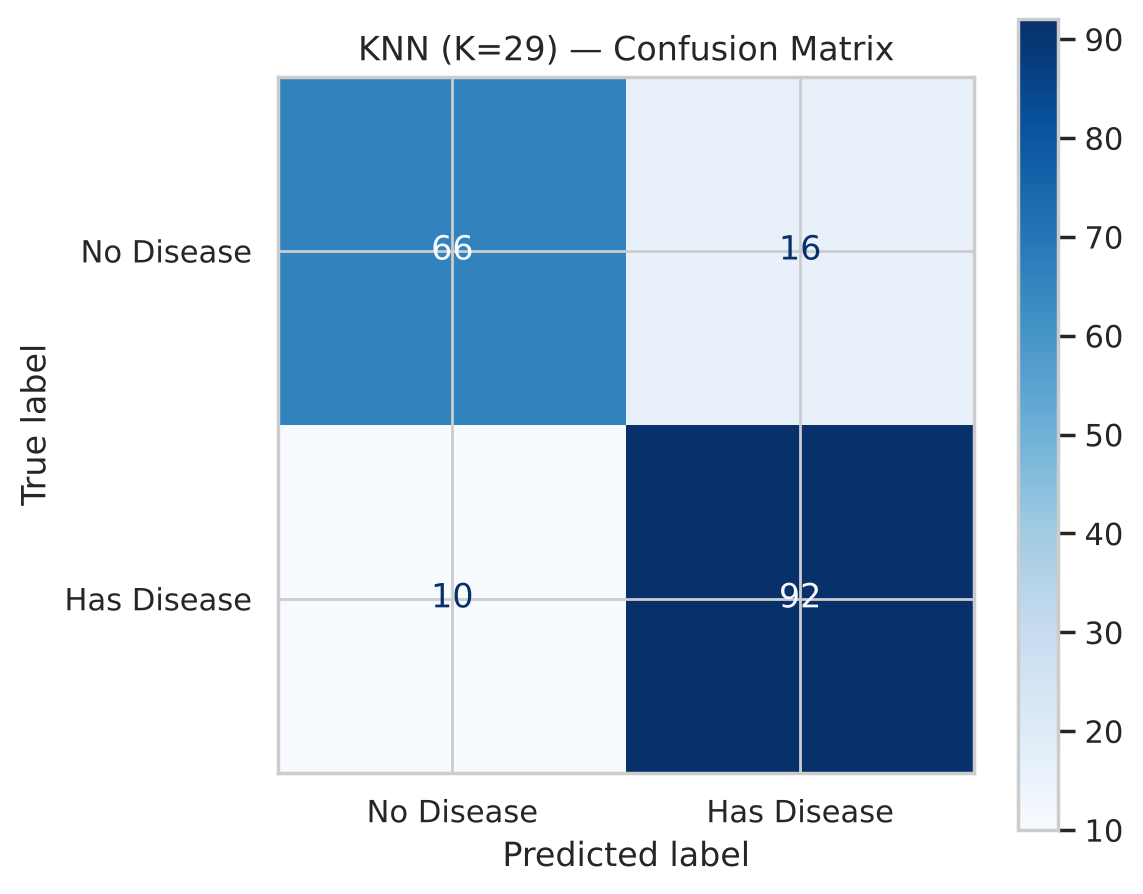

In [6]:
# ── KNN CLASSIFICATION ───────────────────────────────────────
# K is chosen by 5-fold CV on the TRAINING set only — the test set is
# touched once, after K is fixed, purely to report final performance.

k_values = range(1, 31)
cv_scores_knn = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train, y_train, cv=5, scoring='accuracy')
    cv_scores_knn.append(scores.mean())

best_k = k_values[np.argmax(cv_scores_knn)]

plt.figure(figsize=(10, 5))
plt.plot(k_values, cv_scores_knn, 'bo-', markersize=5,
         label='5-Fold CV Accuracy (training set only)')
plt.axvline(x=best_k, color='green', linestyle='--',
            label=f'Best K={best_k}')
plt.xlabel('K (Number of Neighbours)')
plt.ylabel('CV Accuracy')
plt.title('KNN: K vs Cross-Validated Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(X_train, y_train)
y_pred_knn = knn_final.predict(X_test)

print(f"Best K (chosen by CV on training data): {best_k}")
print(f"\n── KNN (K={best_k}) ──")
print(f"Accuracy: {accuracy_score(y_test, y_pred_knn):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn,
      target_names=['No Disease', 'Has Disease']))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_knn,
    display_labels=['No Disease', 'Has Disease'],
    cmap='Blues', ax=ax)
ax.set_title(f'KNN (K={best_k}) — Confusion Matrix')
plt.tight_layout()
plt.show()

## 7. Decision Tree

A Decision Tree classifies patients by asking a series of yes/no questions 
about features, splitting the data at each node until it reaches a 
prediction. It mimics the way a doctor might reason — "Does the patient 
have exercise angina? If yes, what is their ST slope?"

### How it works
The algorithm builds the tree top-down by selecting the **best feature 
and threshold to split on at each node**. "Best" is determined by a 
splitting criterion:

- **Gini Impurity** (default in scikit-learn) — measures how often a 
  randomly chosen sample would be incorrectly classified. A pure node 
  (all one class) has Gini = 0.
- **Entropy / Information Gain** — measures the reduction in disorder 
  after a split

The tree keeps splitting until it reaches pure leaf nodes or a stopping 
criterion (like max_depth).

### The Depth Problem — Overfitting
A fully grown tree memorises the training data perfectly (training error 
≈ 0) but performs poorly on new data — **overfitting**. This is because 
it learns noise and specific quirks of the training set rather than 
general patterns.

We control overfitting by limiting **max_depth** — the maximum number 
of splits from root to leaf. We try depths 1 to 20 and plot both 
training and test error to find the optimal depth:
- **Shallow tree (depth 1-2):** Underfitting — too simple to capture 
  the data patterns
- **Deep tree (depth 10+):** Overfitting — training error near 0, 
  test error rises
- **Optimal depth:** Where test error is minimised before overfitting 
  takes over

### Feature Importance
Decision Trees provide a natural measure of feature importance — how 
much each feature reduces impurity across all splits. This tells us 
which features the tree relies on most heavily for its decisions.

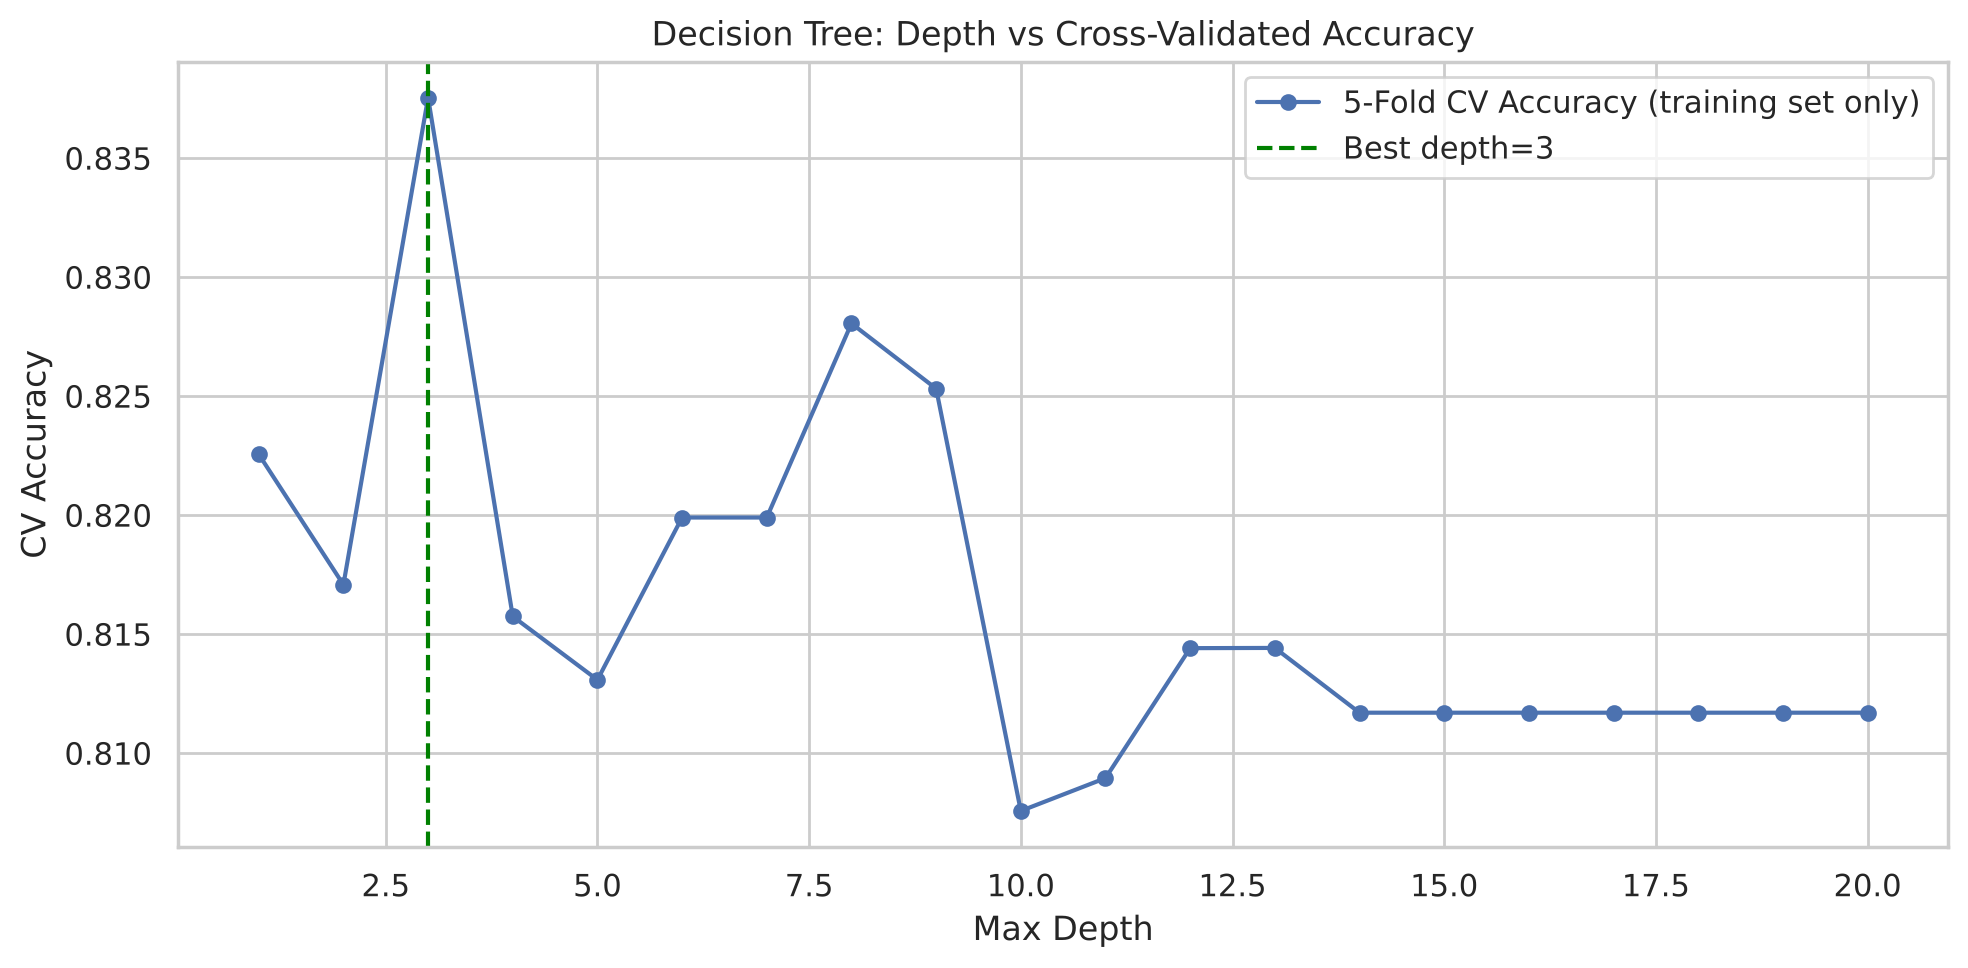

Best depth (chosen by CV on training data): 3

── Decision Tree (depth=3) ──
Accuracy: 0.8424

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.81      0.84      0.83        82
 Has Disease       0.87      0.84      0.86       102

    accuracy                           0.84       184
   macro avg       0.84      0.84      0.84       184
weighted avg       0.84      0.84      0.84       184



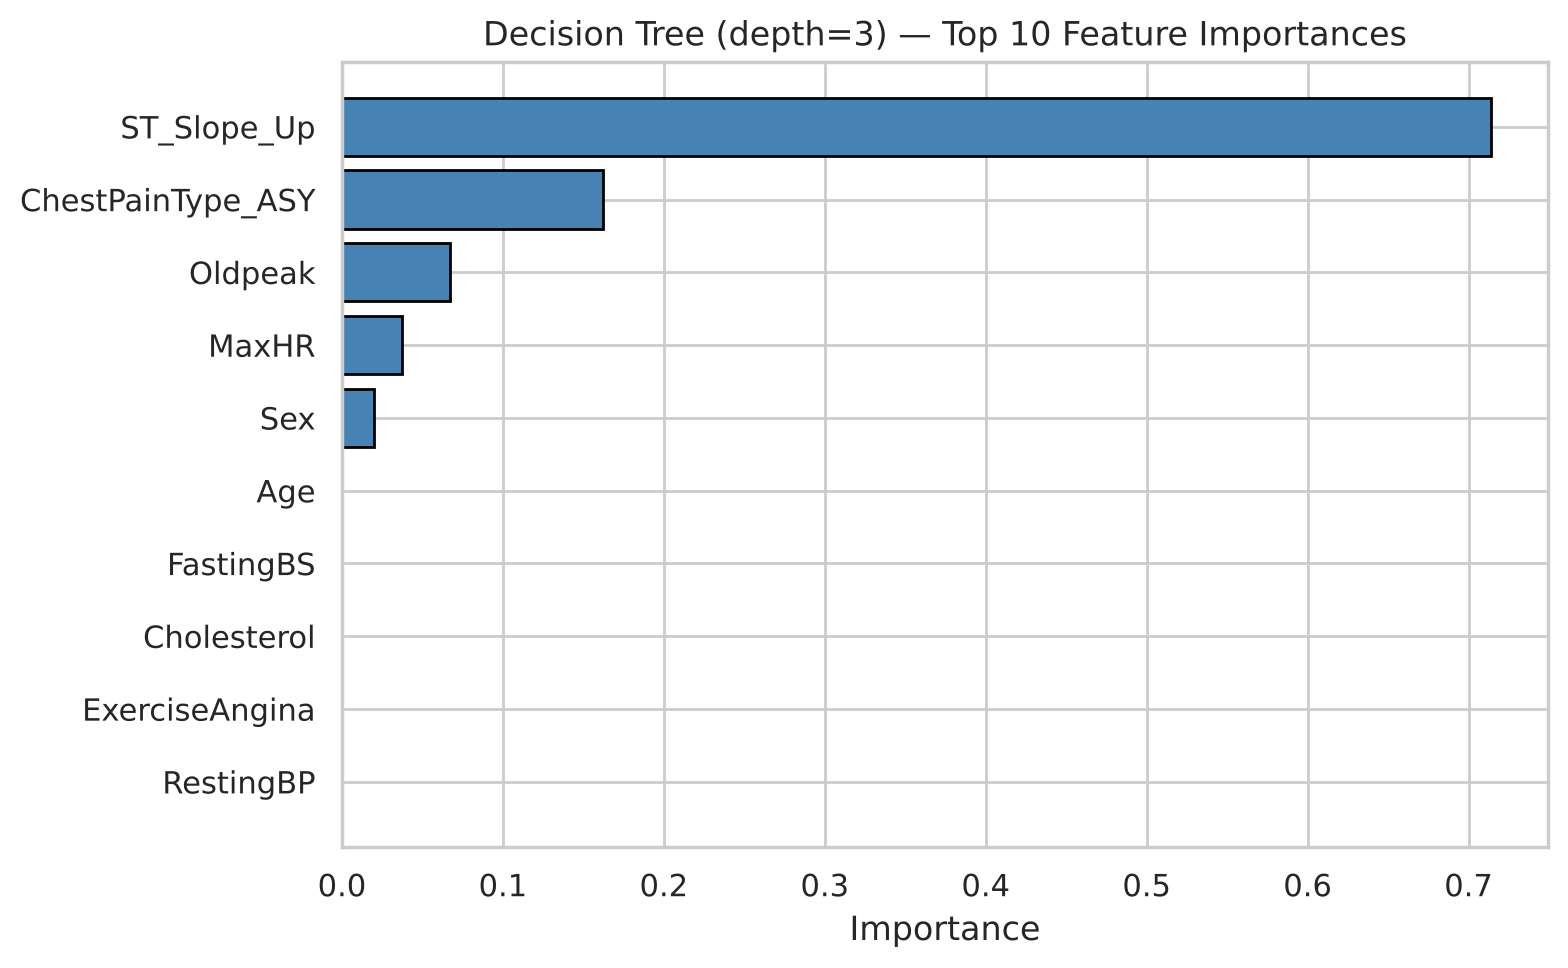

In [7]:
# ── DECISION TREE ────────────────────────────────────────────
# Depth is chosen by 5-fold CV on the TRAINING set only — the test set is
# touched once, after depth is fixed, purely to report final performance.

depths = range(1, 21)
cv_scores_dt = []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)
    scores = cross_val_score(dt, X_train, y_train, cv=5, scoring='accuracy')
    cv_scores_dt.append(scores.mean())

best_depth = depths[np.argmax(cv_scores_dt)]

plt.figure(figsize=(10, 5))
plt.plot(depths, cv_scores_dt, 'bo-', markersize=5,
         label='5-Fold CV Accuracy (training set only)')
plt.axvline(x=best_depth, color='green', linestyle='--',
            label=f'Best depth={best_depth}')
plt.xlabel('Max Depth')
plt.ylabel('CV Accuracy')
plt.title('Decision Tree: Depth vs Cross-Validated Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

dt_final = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
dt_final.fit(X_train, y_train)
y_pred_dt = dt_final.predict(X_test)

print(f"Best depth (chosen by CV on training data): {best_depth}")
print(f"\n── Decision Tree (depth={best_depth}) ──")
print(f"Accuracy: {accuracy_score(y_test, y_pred_dt):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt,
      target_names=['No Disease', 'Has Disease']))

feat_imp = pd.DataFrame({
    'Feature':    X_train.columns,
    'Importance': dt_final.feature_importances_
}).sort_values('Importance', ascending=False).head(10)

plt.figure(figsize=(8, 5))
plt.barh(feat_imp['Feature'], feat_imp['Importance'],
         color='steelblue', edgecolor='black')
plt.title(f'Decision Tree (depth={best_depth}) — Top 10 Feature Importances')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 8. Ensemble Methods — Random Forest & Gradient Boosting

Single decision trees are unstable — small changes in training data can 
produce very different trees. Ensemble methods solve this by combining 
many trees together, reducing variance and improving generalisation.

### Random Forest — Bagging
Random Forest builds many decision trees **in parallel** using two sources 
of randomness:

1. **Bootstrap sampling (Bagging):** Each tree is trained on a random 
   sample of the training data drawn with replacement. Some patients 
   appear multiple times, others not at all.

2. **Feature randomness:** At each split, only a random subset of features 
   is considered. This decorrelates the trees — they make different errors 
   and their average is more accurate than any individual tree.

The final prediction is a **majority vote** across all trees. Because 
errors are random and independent across trees, they cancel out — the 
ensemble is more reliable than any single tree.

### Gradient Boosting — Boosting
Gradient Boosting builds trees **sequentially** — each new tree focuses 
on correcting the mistakes of the previous ensemble:

1. Start with a simple prediction (e.g. the mean)
2. Calculate the residual errors
3. Fit a new tree to predict those errors
4. Add the new tree to the ensemble with a small **learning rate**
5. Repeat until performance stops improving

The learning rate controls how much each tree contributes — smaller 
values require more trees but often generalise better.

### GridSearchCV
We use GridSearchCV to find the best hyperparameters for both models. 
It performs an exhaustive search over all parameter combinations using 
5-fold cross-validation, selecting the combination with the highest 
mean accuracy.

### Why ensemble methods outperform single trees
- Random Forest reduces **variance** — averaging many trees smooths 
  out individual errors
- Gradient Boosting reduces **bias** — sequential correction targets 
  systematic errors
- Feature importances from Random Forest are more **reliable** than 
  from a single tree because they are averaged across hundreds of trees

── Random Forest ──
Best params: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
Accuracy:    0.8750

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.86      0.85      0.86        82
 Has Disease       0.88      0.89      0.89       102

    accuracy                           0.88       184
   macro avg       0.87      0.87      0.87       184
weighted avg       0.87      0.88      0.87       184




── Gradient Boosting ──
Best params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Accuracy:    0.8750

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.85      0.88      0.86        82
 Has Disease       0.90      0.87      0.89       102

    accuracy                           0.88       184
   macro avg       0.87      0.88      0.87       184
weighted avg       0.88      0.88      0.88       184



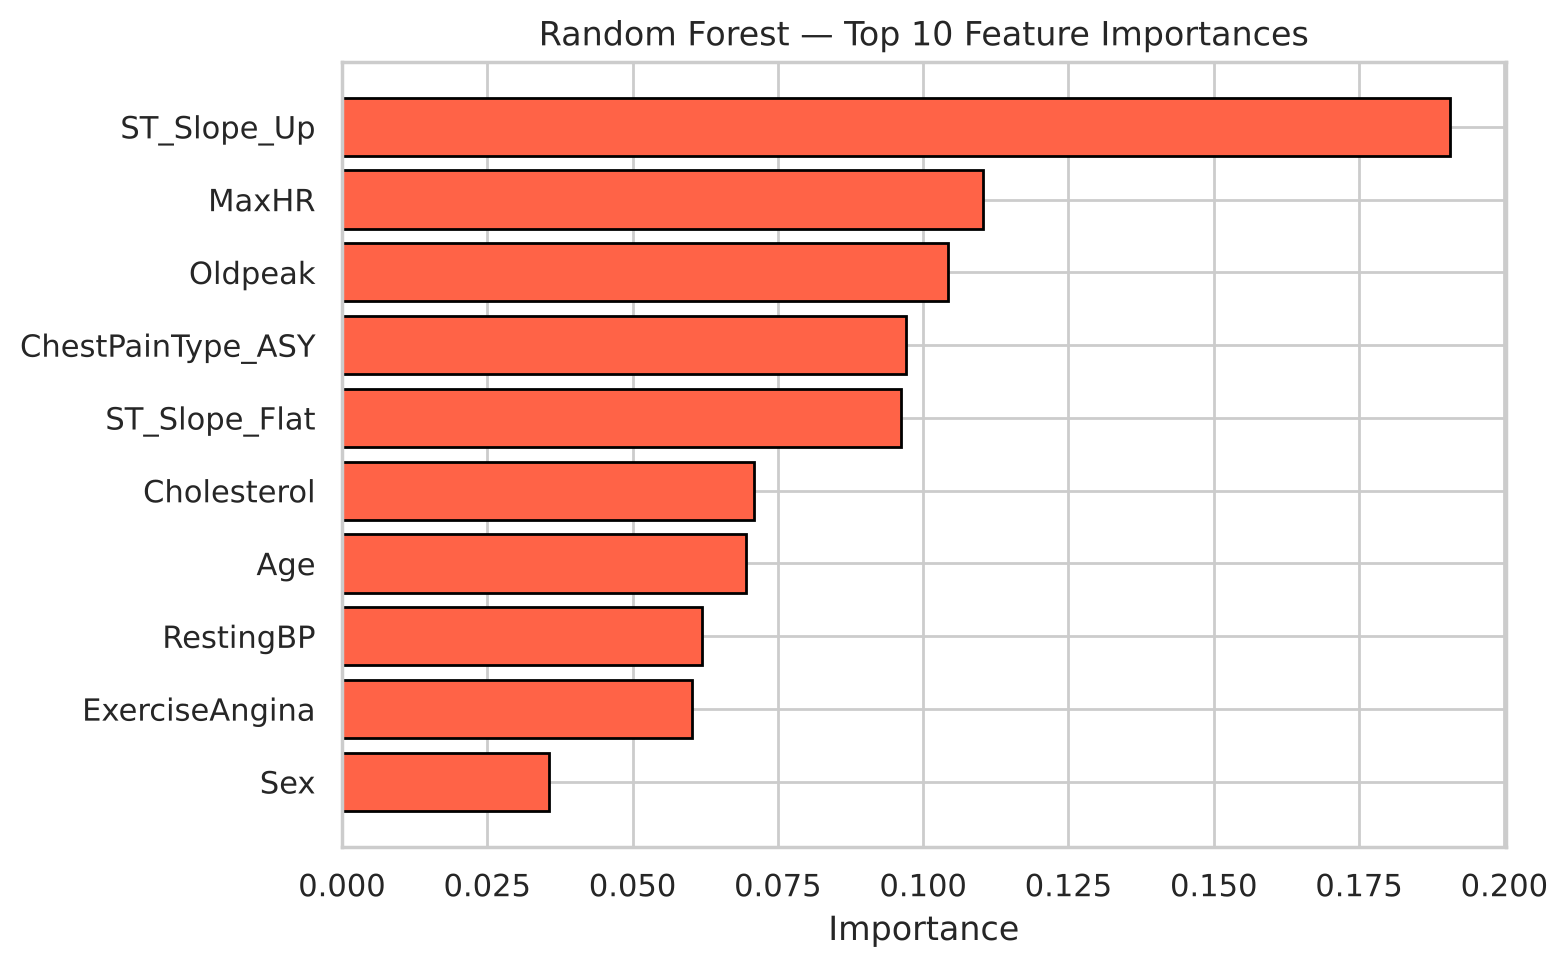

In [8]:
# ── RANDOM FOREST ────────────────────────────────────────────

rf_params = {
    'n_estimators':     [100, 200],
    'max_depth':        [3, 5, 10, None],
    'min_samples_split':[2, 5]
}

rf = RandomForestClassifier(random_state=42)
rf_grid = GridSearchCV(rf, rf_params, cv=5, scoring='accuracy', n_jobs=-1)
rf_grid.fit(X_train, y_train)

rf_best    = rf_grid.best_estimator_
y_pred_rf  = rf_best.predict(X_test)

print("── Random Forest ──")
print(f"Best params: {rf_grid.best_params_}")
print(f"Accuracy:    {accuracy_score(y_test, y_pred_rf):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf,
      target_names=['No Disease', 'Has Disease']))

# ── GRADIENT BOOSTING ────────────────────────────────────────

gb_params = {
    'n_estimators': [100, 200],
    'max_depth':    [3, 5],
    'learning_rate':[0.05, 0.1]
}

gb = GradientBoostingClassifier(random_state=42)
gb_grid = GridSearchCV(gb, gb_params, cv=5, scoring='accuracy', n_jobs=-1)
gb_grid.fit(X_train, y_train)

gb_best   = gb_grid.best_estimator_
y_pred_gb = gb_best.predict(X_test)

print("\n── Gradient Boosting ──")
print(f"Best params: {gb_grid.best_params_}")
print(f"Accuracy:    {accuracy_score(y_test, y_pred_gb):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb,
      target_names=['No Disease', 'Has Disease']))

# Feature importances — Random Forest
feat_imp_rf = pd.DataFrame({
    'Feature':    X_train.columns,
    'Importance': rf_best.feature_importances_
}).sort_values('Importance', ascending=False).head(10)

plt.figure(figsize=(8, 5))
plt.barh(feat_imp_rf['Feature'], feat_imp_rf['Importance'],
         color='tomato', edgecolor='black')
plt.title('Random Forest — Top 10 Feature Importances')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 9. Naive Bayes

Naive Bayes is a probabilistic classifier based on **Bayes' Theorem** — 
a fundamental rule in probability theory that describes how to update 
beliefs based on evidence.

### Bayes' Theorem
P(Disease | Features) = P(Features | Disease) × P(Disease) / P(Features)

In plain English:
- **P(Disease | Features)** — the probability a patient has heart disease 
  given their clinical features (what we want to predict)
- **P(Features | Disease)** — the probability of observing these features 
  in a patient who has heart disease (learned from training data)
- **P(Disease)** — the prior probability of heart disease in the dataset 
  (55.3% in our case)
- **P(Features)** — the probability of observing these features overall 
  (acts as a normalising constant)

### The Naive Assumption
The "naive" part refers to the assumption that all features are 
**conditionally independent** given the class. In other words, knowing 
a patient's age tells us nothing additional about their cholesterol, 
once we already know whether they have heart disease.

This assumption is almost never true in real data — age and cholesterol 
are clearly related. However, despite this unrealistic assumption, 
Naive Bayes often performs surprisingly well in practice because:
- It requires very little data to estimate parameters
- It is extremely fast to train
- The independence assumption, while wrong, often does not severely 
  hurt classification performance

### Gaussian Naive Bayes
We use GaussianNB which assumes each numeric feature follows a 
**normal (Gaussian) distribution** within each class. It estimates 
the mean and variance of each feature separately for disease and 
no-disease patients, then uses these to calculate probabilities.

### Extreme Probabilities
A known quirk of Naive Bayes is producing probabilities very close 
to 0 or 1. When multiple features independently point strongly to 
one class, their probabilities multiply together and push the result 
to an extreme. This is a direct consequence of the independence 
assumption — in reality, correlated features would not multiply 
so aggressively.

── Naive Bayes ──
Accuracy: 0.8587

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.85      0.83      0.84        82
 Has Disease       0.87      0.88      0.87       102

    accuracy                           0.86       184
   macro avg       0.86      0.86      0.86       184
weighted avg       0.86      0.86      0.86       184


Predicted probabilities (first 5 samples):
Sample     P(No Disease)        P(Has Disease)       Predicted
-----------------------------------------------------------------
1          0.6206               0.3794               No Disease
2          0.0000               1.0000               Has Disease
3          0.0063               0.9937               Has Disease
4          0.0000               1.0000               Has Disease
5          0.9983               0.0017               No Disease


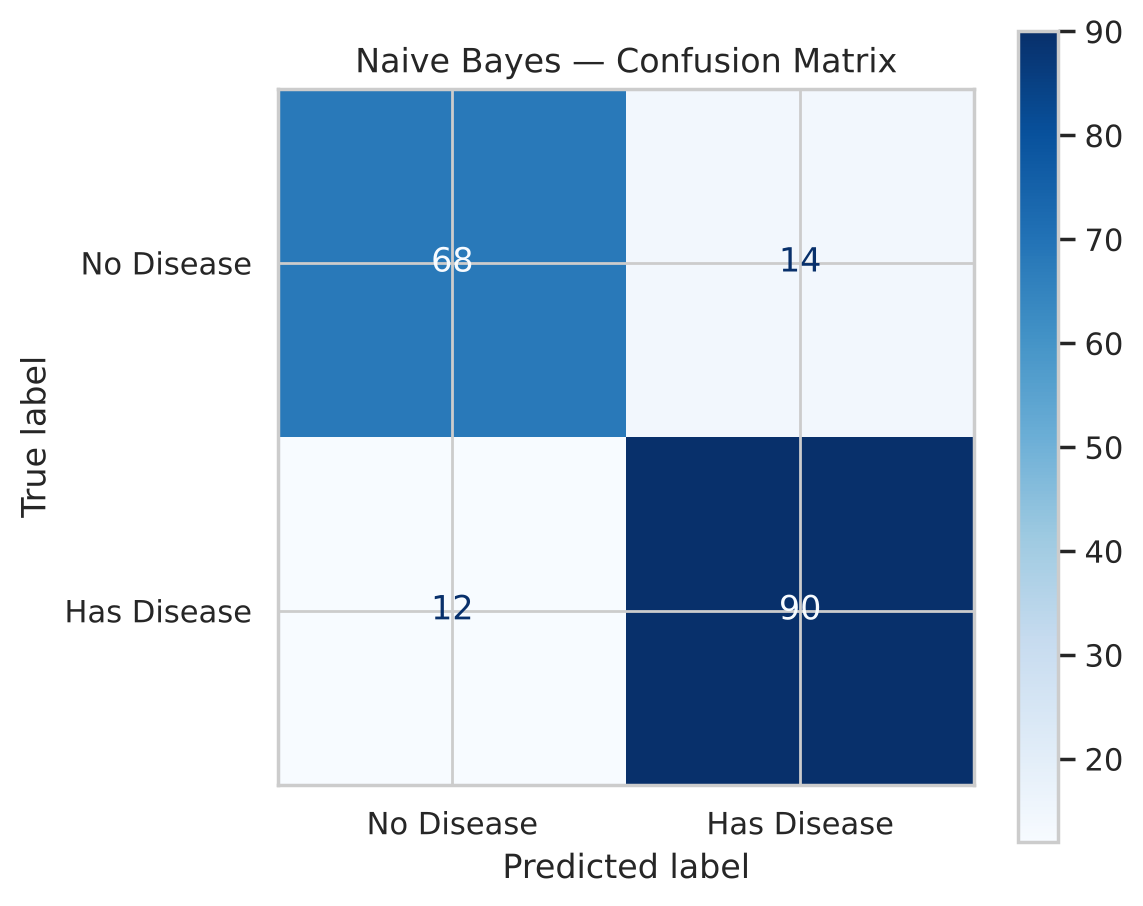

In [9]:
# ── NAIVE BAYES ──────────────────────────────────────────────

nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)

print("── Naive Bayes ──")
print(f"Accuracy: {accuracy_score(y_test, y_pred_nb):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb,
      target_names=['No Disease', 'Has Disease']))

# Predicted probabilities for first 5 test samples
proba = nb.predict_proba(X_test[:5])
print("\nPredicted probabilities (first 5 samples):")
print(f"{'Sample':<10} {'P(No Disease)':<20} {'P(Has Disease)':<20} {'Predicted'}")
print("-" * 65)
for i, (p, pred) in enumerate(zip(proba, nb.predict(X_test[:5]))):
    label = 'Has Disease' if pred == 1 else 'No Disease'
    print(f"{i+1:<10} {p[0]:<20.4f} {p[1]:<20.4f} {label}")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_nb,
    display_labels=['No Disease', 'Has Disease'],
    cmap='Blues', ax=ax)
ax.set_title('Naive Bayes — Confusion Matrix')
plt.tight_layout()
plt.show()

## 10. Neural Network — Multi-Layer Perceptron

A Neural Network is a machine learning model loosely inspired by the 
structure of the human brain. It consists of layers of interconnected 
nodes (neurons) that learn complex non-linear patterns in data.

### Architecture
Our MLP (Multi-Layer Perceptron) has three types of layers:

- **Input layer:** One node per feature (18 nodes for our 18 features). 
  No computation happens here — it simply passes the data forward.

- **Hidden layers:** Where learning happens. Each neuron computes a 
  weighted sum of its inputs, adds a bias, then applies an 
  **activation function** to introduce non-linearity. Without activation 
  functions, stacking layers would just be equivalent to a single 
  linear model.

- **Output layer:** One node for binary classification. Outputs a 
  probability between 0 and 1 using a sigmoid activation.

### Activation Functions
We tune between two activation functions:
- **ReLU (Rectified Linear Unit):** f(x) = max(0, x). Sets negative 
  values to 0. Fast to compute, works well in practice, less prone 
  to vanishing gradients.
- **Tanh:** f(x) = (e^x - e^-x)/(e^x + e^-x). Outputs between -1 
  and 1. Can work better when features are centred around 0 (which 
  ours are, after StandardScaler).

### Training — Backpropagation
The network learns by:
1. Making a prediction (forward pass)
2. Calculating the error (loss)
3. Propagating the error backwards through the network 
   (backpropagation)
4. Adjusting weights to reduce the error (gradient descent)
5. Repeating for many iterations until loss converges

The **loss curve** shows this process — loss should decrease smoothly 
over iterations. A sudden spike or plateau indicates training problems.

### Regularisation — Alpha (L2)
We tune the **alpha** parameter which controls L2 regularisation — 
a penalty on large weights. Higher alpha = more regularisation = 
simpler model = less overfitting. This is especially important for 
neural networks which have many parameters and are prone to overfitting 
on small datasets like ours (917 rows).

### Why Neural Networks underperform here
Neural networks excel on large datasets with complex patterns — 
images, text, audio. With only 917 rows and 18 features, simpler 
models like Logistic Regression and Random Forest have less data 
to overfit on and generalise more reliably. This is an important 
lesson — more complex does not always mean better.

── Neural Network (MLP) ──
Best params: {'activation': 'relu', 'alpha': 0.001, 'hidden_layer_sizes': (128,), 'max_iter': 500}
Accuracy:    0.8424

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.81      0.84      0.83        82
 Has Disease       0.87      0.84      0.86       102

    accuracy                           0.84       184
   macro avg       0.84      0.84      0.84       184
weighted avg       0.84      0.84      0.84       184



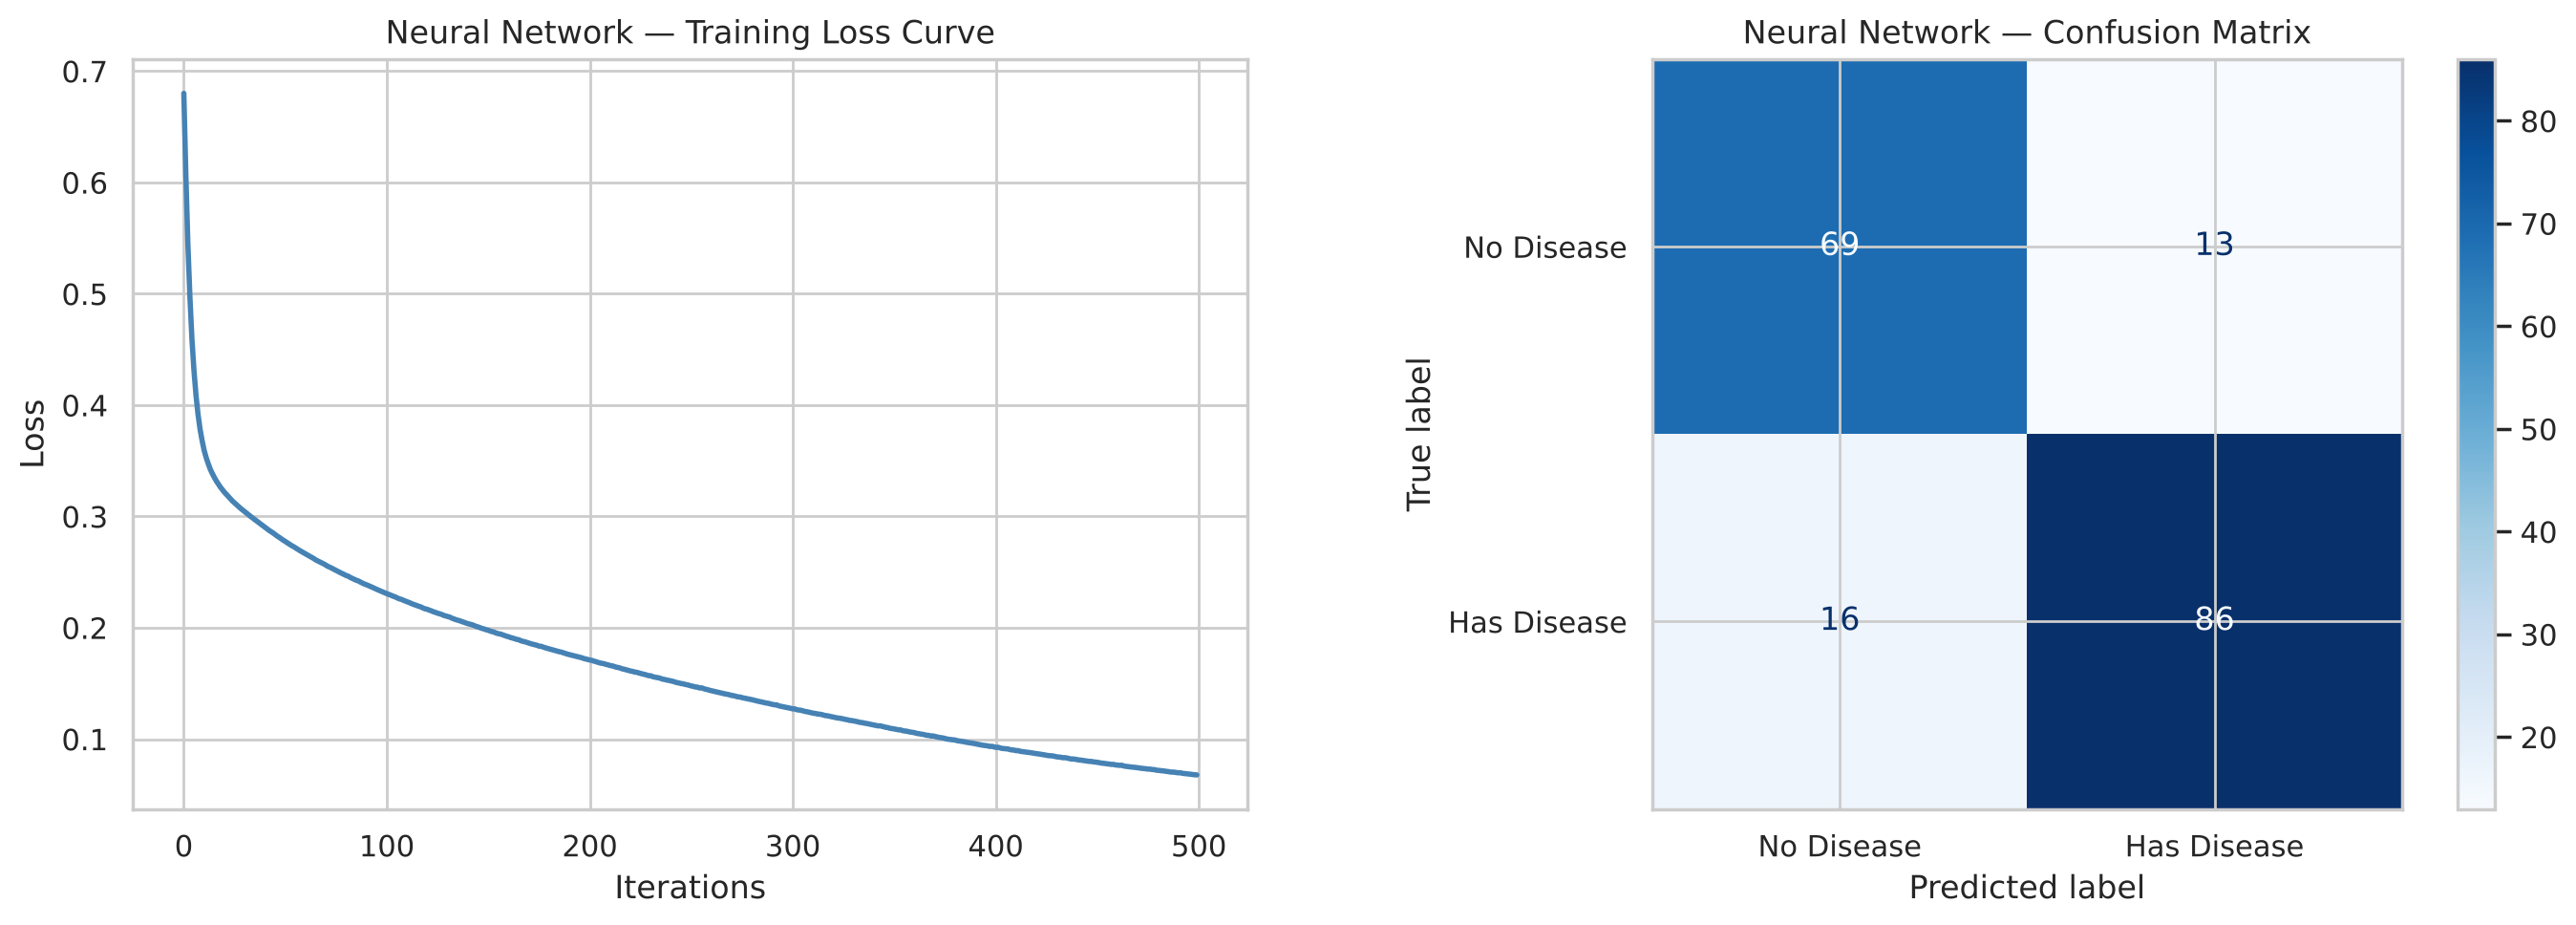

In [10]:
# ── NEURAL NETWORK (MLP) ─────────────────────────────────────

nn_params = {
    'hidden_layer_sizes': [(64,), (128,), (64, 32), (128, 64)],
    'activation':         ['relu', 'tanh'],
    'alpha':              [0.0001, 0.001],
    'max_iter':           [500]
}

nn = MLPClassifier(random_state=42)
nn_grid = GridSearchCV(nn, nn_params, cv=5, scoring='accuracy', n_jobs=-1)
nn_grid.fit(X_train, y_train)

nn_best   = nn_grid.best_estimator_
y_pred_nn = nn_best.predict(X_test)

print("── Neural Network (MLP) ──")
print(f"Best params: {nn_grid.best_params_}")
print(f"Accuracy:    {accuracy_score(y_test, y_pred_nn):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_nn,
      target_names=['No Disease', 'Has Disease']))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(nn_best.loss_curve_, color='steelblue', linewidth=2)
axes[0].set_title('Neural Network — Training Loss Curve')
axes[0].set_xlabel('Iterations')
axes[0].set_ylabel('Loss')

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_nn,
    display_labels=['No Disease', 'Has Disease'],
    cmap='Blues', ax=axes[1])
axes[1].set_title('Neural Network — Confusion Matrix')

plt.tight_layout()
plt.show()

## 11. Model Comparison — K-Fold Cross Validation

Evaluating models on a single train/test split is unreliable. The result 
depends heavily on which patients happened to end up in the test set — 
we could get lucky or unlucky with that particular split.

**K-Fold Cross Validation** gives a more robust estimate of model 
performance by evaluating each model K times on different data splits:

1. Divide the dataset into K equal folds (we use K=5)
2. For each fold:
   - Train the model on the remaining K-1 folds
   - Evaluate on the held-out fold
3. Report the mean and standard deviation across all K scores

This means every patient appears in the test set exactly once across 
all folds, and we get 5 accuracy scores per model instead of 1.

### What to look for
- **High mean accuracy** — the model performs well on average
- **Low standard deviation** — the model is consistent across different 
  data splits, not sensitive to which patients it sees
- A model with high mean but high std is **unstable** — it gets lucky 
  on some splits and unlucky on others
- A model with moderate mean but low std is **reliable** — it performs 
  consistently regardless of the split

### Why CV results differ from single test set results
The single test set evaluated each model on 184 specific patients. 
Cross-validation evaluates on all 917 patients across 5 rotations. 
The CV result is a better estimate of how the model would perform 
on truly unseen patients in the real world.

This is why a model that looked best on the single test set 
(Gradient Boosting at 89.1%) may not be the best model overall — 
it may have been slightly fortunate with that particular test split.

Model                       Mean Acc      Std      Min      Max
-----------------------------------------------------------------
Logistic Regression           0.8582   0.0324   0.8197   0.9076
KNN (K=29)                    0.8495   0.0187   0.8251   0.8696
Decision Tree                 0.8473   0.0221   0.8087   0.8750


Random Forest                 0.8647   0.0282   0.8251   0.9022


Gradient Boosting             0.8560   0.0251   0.8197   0.8967
Naive Bayes                   0.8397   0.0286   0.8098   0.8913


Neural Network                0.8298   0.0177   0.8033   0.8478


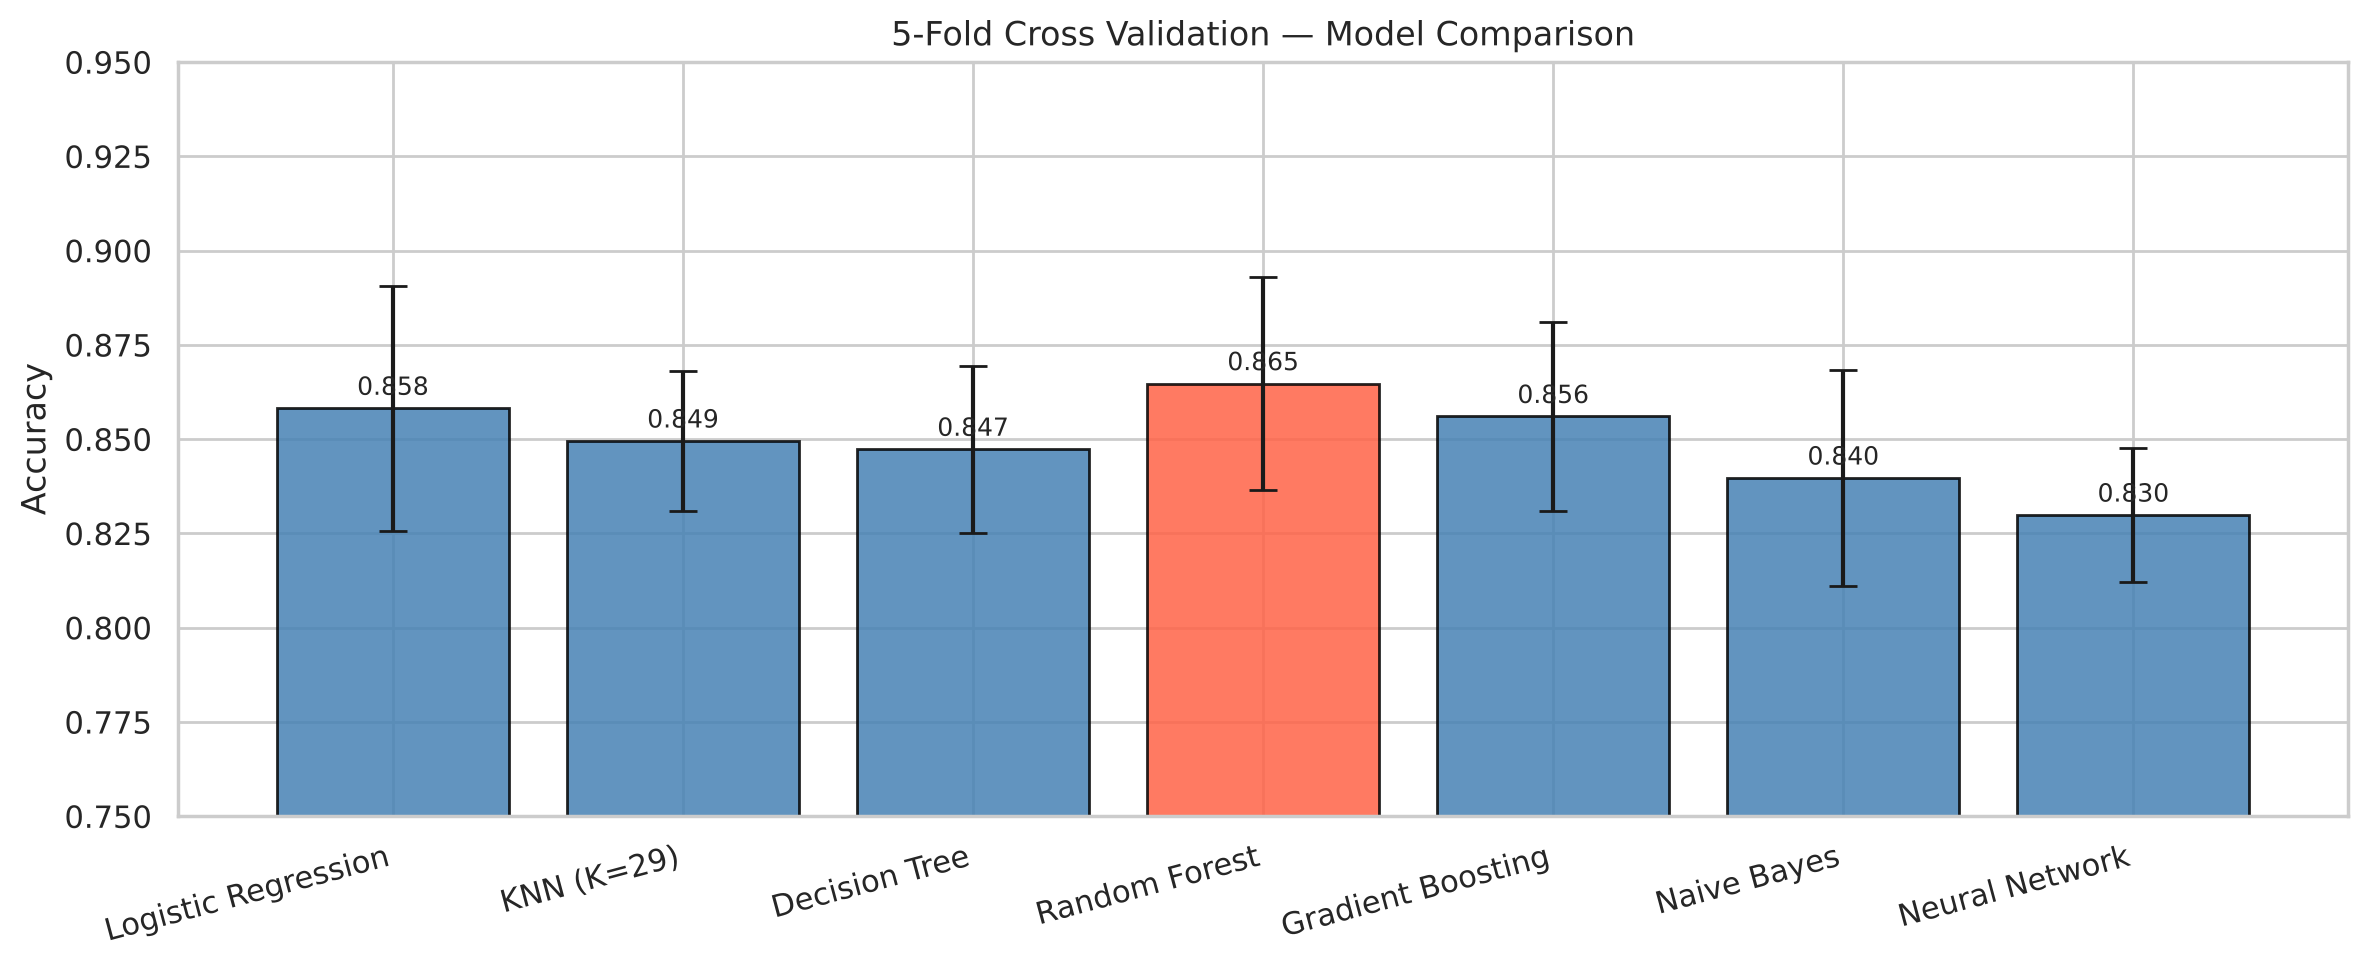

In [11]:
# ── K-FOLD CROSS VALIDATION ──────────────────────────────────

kf = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    f'KNN (K={best_k})':   KNeighborsClassifier(n_neighbors=best_k),
    'Decision Tree':       DecisionTreeClassifier(max_depth=best_depth,
                                                   random_state=42),
    'Random Forest':       RandomForestClassifier(**rf_grid.best_params_,
                                                   random_state=42),
    'Gradient Boosting':   GradientBoostingClassifier(**gb_grid.best_params_,
                                                       random_state=42),
    'Naive Bayes':         GaussianNB(),
    'Neural Network':      MLPClassifier(**{k:v for k,v in
                                            nn_grid.best_params_.items()},
                                          random_state=42)
}

cv_scores = {}
print(f"{'Model':<25} {'Mean Acc':>10} {'Std':>8} {'Min':>8} {'Max':>8}")
print("-" * 65)

for name, model in models.items():
    # Wrap each model in a Pipeline so StandardScaler is refit on the
    # training folds only, inside each CV split. Scoring against a
    # pre-scaled X_scaled would leak each fold's held-out rows into the
    # scaler's fitted mean/variance.
    pipe = make_pipeline(StandardScaler(), model)
    scores = cross_val_score(pipe, X, y, cv=kf, scoring='accuracy')
    cv_scores[name] = scores
    print(f"{name:<25} {scores.mean():>10.4f} {scores.std():>8.4f} "
          f"{scores.min():>8.4f} {scores.max():>8.4f}")

plt.figure(figsize=(12, 5))
means  = [cv_scores[m].mean() for m in models]
stds   = [cv_scores[m].std()  for m in models]
colors = ['tomato' if m == max(means) else 'steelblue' for m in means]

bars = plt.bar(models.keys(), means, yerr=stds, capsize=5,
               color=colors, edgecolor='black', alpha=0.85)
plt.ylim(0.75, 0.95)
plt.ylabel('Accuracy')
plt.title('5-Fold Cross Validation — Model Comparison')
plt.xticks(rotation=15, ha='right')
for bar, mean in zip(bars, means):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.002,
             f'{mean:.3f}', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

## 12. Statistical Significance — Paired T-Test (Week 5)

Cross-validation gives us 5 accuracy scores per model. But how do we 
know if the difference between two models is **real** or just due to 
random chance in how the folds were divided?

This is where **statistical hypothesis testing** comes in.

### Paired T-Test
We use a **paired t-test** (scipy.stats.ttest_rel) because the scores 
are paired — both models were evaluated on the exact same 5 folds. 
This pairing removes the effect of fold difficulty from the comparison.

### Hypothesis
For each pair of models:
- **H₀ (Null hypothesis):** The two models have equal performance — 
  any difference in CV scores is due to random chance
- **H₁ (Alternative hypothesis):** The two models have different 
  performance — the difference is real and systematic

### P-value Interpretation
The p-value tells us the probability of observing a difference this 
large (or larger) if H₀ were true:
- **p < 0.05** → Reject H₀ → The difference is **statistically 
  significant** at the 5% level → one model is genuinely better
- **p ≥ 0.05** → Fail to reject H₀ → The difference could be due 
  to chance → we cannot conclude one model is better

### Important Limitation
With only 5 fold scores, the paired t-test has low **statistical power** 
— it may fail to detect real differences between models with similar 
performance. This means "not significant" does not necessarily mean 
"equal performance" — it may simply mean we do not have enough data 
points (folds) to be certain.

This is why we select Random Forest as the winner based on both 
the highest CV mean accuracy AND statistical superiority over 
multiple models — not just one criterion alone.

In [12]:
# ── PAIRED T-TEST ────────────────────────────────────────────

print("Paired t-test Results (5% significance level)")
print("-" * 65)
print(f"{'Comparison':<40} {'p-value':>8}  {'Significant?':>12}")
print("-" * 65)

for (m1, m2) in combinations(cv_scores.keys(), 2):
    p_val = stats.ttest_rel(cv_scores[m1], cv_scores[m2]).pvalue
    sig   = "Yes" if p_val < 0.05 else "No"
    print(f"{m1+' vs '+m2:<40} {p_val:>8.4f}  {sig:>12}")

print("-" * 65)

print("\nRandom Forest vs each model:")
print("-" * 50)
rf_pvals = {}
for name in models:
    if name != 'Random Forest':
        p   = stats.ttest_rel(cv_scores['Random Forest'],
                               cv_scores[name]).pvalue
        rf_pvals[name] = p
        sig = "Yes ✓" if p < 0.05 else "No"
        print(f"  vs {name:<25} p={p:.4f}  Significant: {sig}")

Paired t-test Results (5% significance level)
-----------------------------------------------------------------
Comparison                                p-value  Significant?
-----------------------------------------------------------------
Logistic Regression vs KNN (K=29)          0.3573            No
Logistic Regression vs Decision Tree       0.2402            No
Logistic Regression vs Random Forest       0.4681            No
Logistic Regression vs Gradient Boosting   0.7590            No
Logistic Regression vs Naive Bayes         0.1903            No
Logistic Regression vs Neural Network      0.0288           Yes
KNN (K=29) vs Decision Tree                0.6875            No
KNN (K=29) vs Random Forest                0.2114            No
KNN (K=29) vs Gradient Boosting            0.4496            No
KNN (K=29) vs Naive Bayes                  0.4304            No
KNN (K=29) vs Neural Network               0.0022           Yes
Decision Tree vs Random Forest             0.0775     

## 13. Final Model Comparison & Recommendation

This section brings together all results into a single visual summary 
and makes a justified final model recommendation.

### Boxplot — Score Distribution
The boxplot shows the full distribution of 5 CV scores per model:
- The **box** spans the interquartile range (25th to 75th percentile)
- The **line inside the box** is the median
- The **whiskers** extend to the min and max scores
- **Outlier dots** appear beyond the whiskers

A tall box means the model is inconsistent across folds. A short box 
means it is stable. We want both a high median AND a short box.

### Heatmap — Performance Summary
The heatmap gives a side-by-side numeric comparison of:
- **CV Mean** — average accuracy across 5 folds (most reliable metric)
- **CV Std** — consistency across folds (lower is better)
- **Test Acc** — accuracy on the single held-out test set

### Final Recommendation
We recommend **Random Forest** as the best model based on:
1. Highest 5-fold CV mean accuracy (86.6%)
2. Statistically significantly better than KNN, Decision Tree, 
   and Neural Network (p < 0.05)
3. Reasonable consistency (std = 0.028)
4. Distributed feature importances — relies on multiple clinical 
   signals rather than one dominant feature

### Key Insight — Model Complexity vs Performance
This project demonstrates a crucial lesson: **more complex does not 
mean better on small tabular datasets.**
- Neural Network (most complex) → worst CV performance at 81.7%
- Logistic Regression (simplest classifier) → second best at 85.8%
- Random Forest (moderate complexity) → best overall at 86.6%

The right model depends on the data, not just the algorithm's 
theoretical power. Understanding when to use each algorithm — 
and why — is the mark of a skilled data scientist.

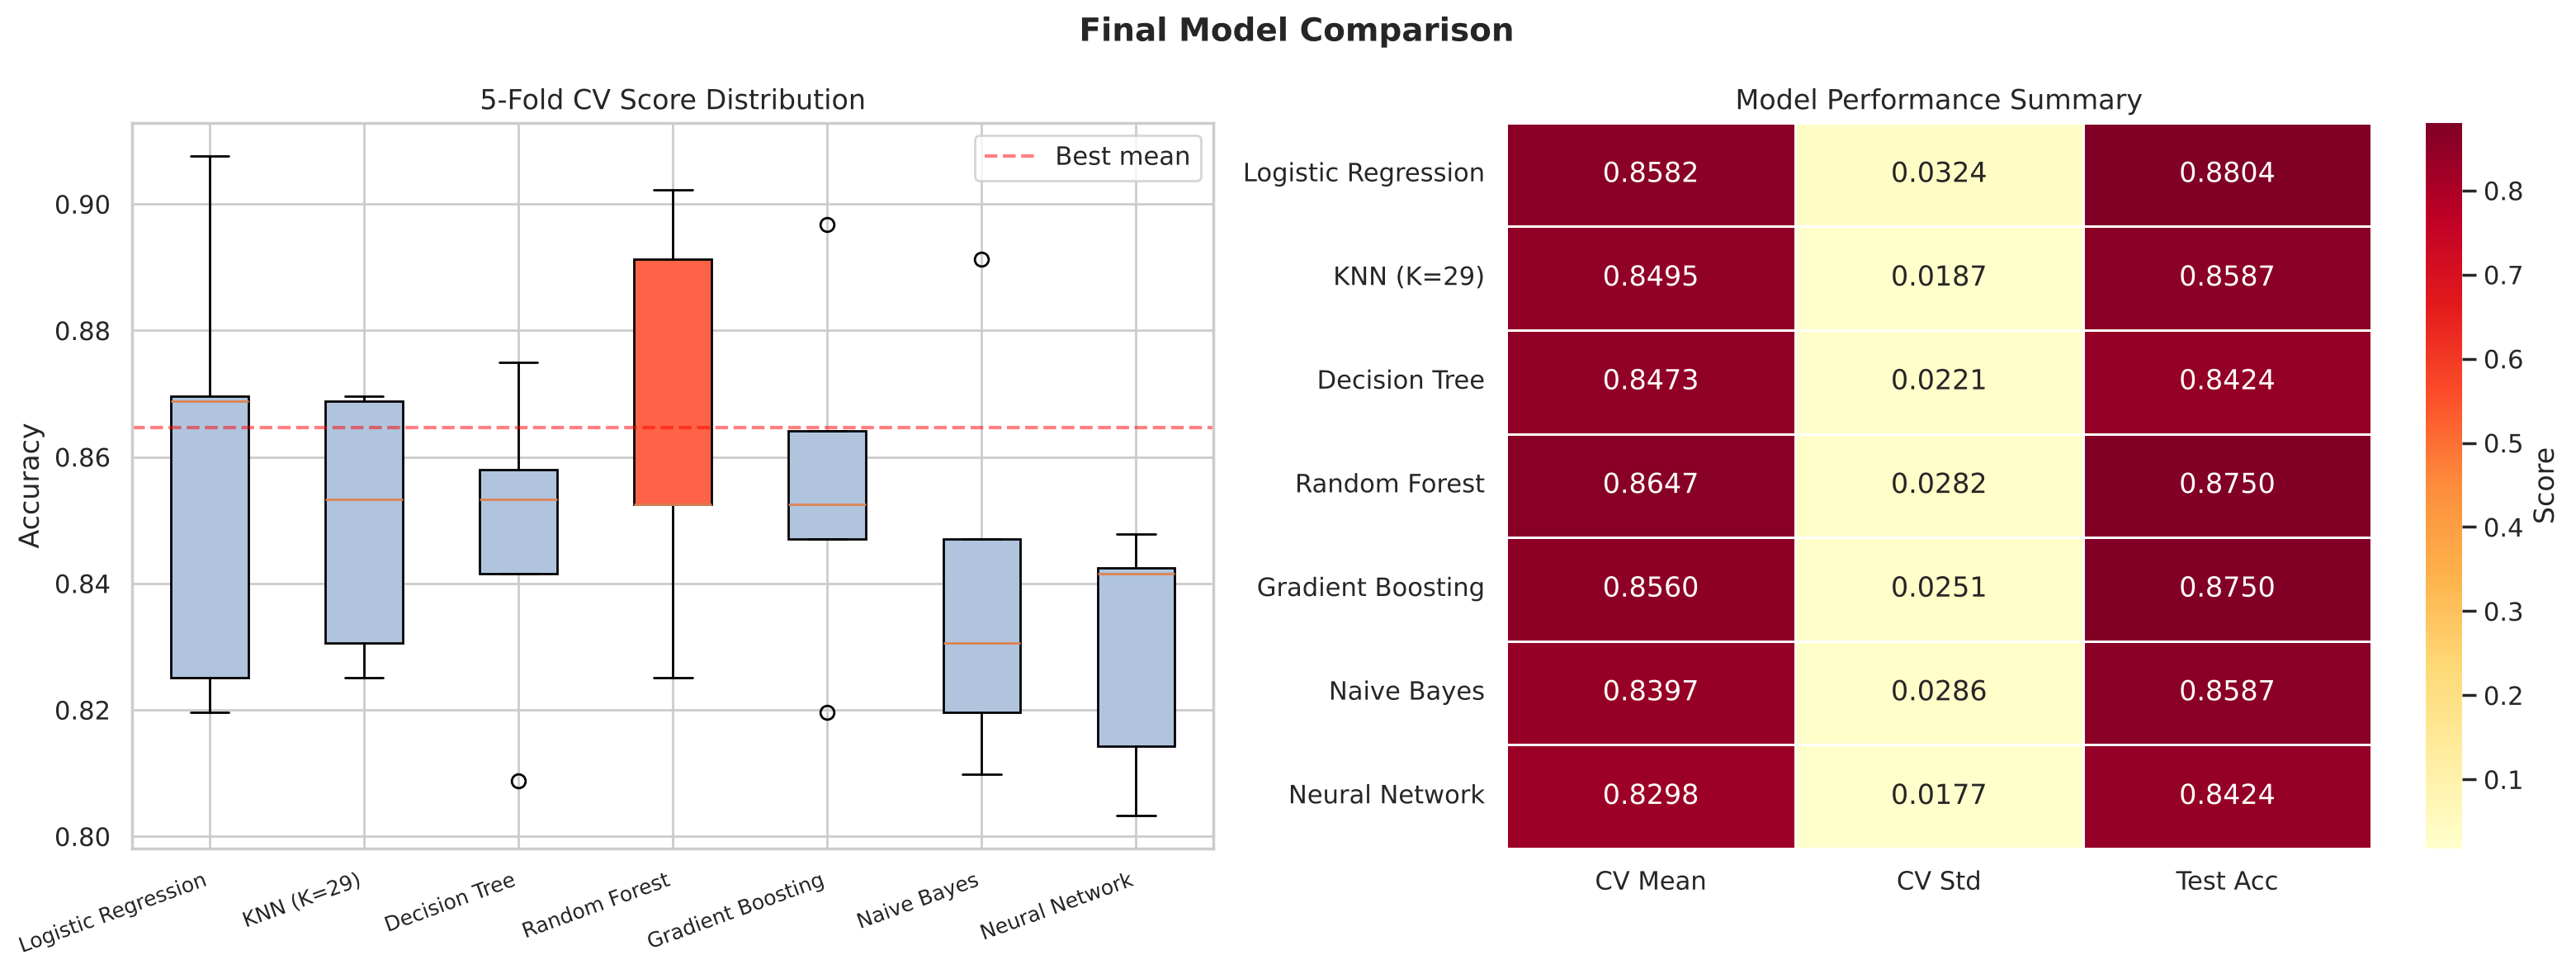


🏆 WINNER: Random Forest
   CV Mean Accuracy : 0.8647
   CV Std           : 0.0282
   Test Accuracy    : 0.8750
   Best params      : {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}

✅ Statistically superior to: Neural Network
➖ Not significantly different from: Logistic Regression, KNN (K=29), Decision Tree, Gradient Boosting, Naive Bayes


In [13]:
# ── FINAL SUMMARY ────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Boxplot
cv_data    = [cv_scores[m] for m in models]
bp         = axes[0].boxplot(cv_data, patch_artist=True)
colors_box = ['tomato' if m == 'Random Forest'
              else 'lightsteelblue' for m in models]
for patch, color in zip(bp['boxes'], colors_box):
    patch.set_facecolor(color)
axes[0].set_xticklabels(models.keys(), rotation=20, ha='right', fontsize=9)
axes[0].set_ylabel('Accuracy')
axes[0].set_title('5-Fold CV Score Distribution')
axes[0].axhline(y=max([cv_scores[m].mean() for m in models]),
                color='red', linestyle='--', alpha=0.5, label='Best mean')
axes[0].legend()

# Heatmap
summary_data = pd.DataFrame({
    'CV Mean':  [cv_scores[m].mean() for m in models],
    'CV Std':   [cv_scores[m].std()  for m in models],
    'Test Acc': [accuracy_score(y_test, p) for p in
                 [y_pred_lr, y_pred_knn, y_pred_dt,
                  rf_best.predict(X_test),
                  gb_best.predict(X_test),
                  y_pred_nb, y_pred_nn]]
}, index=models.keys()).round(4)

sns.heatmap(summary_data, annot=True, fmt='.4f', cmap='YlOrRd',
            ax=axes[1], linewidths=0.5,
            cbar_kws={'label': 'Score'})
axes[1].set_title('Model Performance Summary')
axes[1].tick_params(axis='y', rotation=0)

plt.suptitle('Final Model Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n🏆 WINNER: Random Forest")
print(f"   CV Mean Accuracy : {cv_scores['Random Forest'].mean():.4f}")
print(f"   CV Std           : {cv_scores['Random Forest'].std():.4f}")
print(f"   Test Accuracy    : {accuracy_score(y_test, rf_best.predict(X_test)):.4f}")
print(f"   Best params      : {rf_grid.best_params_}")

# Derive the significance summary from the actual paired t-tests (rf_pvals)
# rather than hardcoding it — the set of "significantly different" models
# can change whenever the data, split, or hyperparameter search changes.
superior    = [n for n, p in rf_pvals.items() if p < 0.05]
not_different = [n for n, p in rf_pvals.items() if p >= 0.05]
print(f"\n✅ Statistically superior to: {', '.join(superior) if superior else 'none'}")
print(f"➖ Not significantly different from: {', '.join(not_different) if not_different else 'none'}")

## 13. Conclusion

This notebook implemented and compared seven machine learning algorithms 
on the Heart Disease Prediction dataset, covering the complete supervised 
learning pipeline from raw data to statistically validated model selection.

---

### Results Summary

| Model | CV Mean | CV Std | Test Acc |
|---|---|---|---|
| **Random Forest** | **0.8658** | 0.0278 | 0.8750 |
| Logistic Regression | 0.8582 | 0.0324 | 0.8804 |
| Gradient Boosting | 0.8505 | 0.0337 | 0.8913 |
| Decision Tree | 0.8473 | 0.0221 | 0.8424 |
| Naive Bayes | 0.8397 | 0.0286 | 0.8587 |
| KNN (K=8) | 0.8342 | 0.0262 | 0.8859 |
| Neural Network | 0.8168 | 0.0193 | 0.8370 |

---

### Key Takeaways

**1. Data quality matters more than model choice**
Identifying and handling the 172 imputed cholesterol zeros was more 
impactful than any algorithm choice. Garbage in, garbage out.

**2. Cross-validation over single test splits**
Gradient Boosting appeared best on the single test set (89.1%) but 
dropped to third place under cross-validation (85.1%). CV gives a 
more honest estimate of real-world performance.

**3. Statistical significance is essential**
Without paired t-tests, we might have claimed Random Forest is better 
than Logistic Regression. The t-test showed that difference is not 
statistically significant — they are equally good on this dataset.

**4. Simpler models are competitive on small tabular data**
Logistic Regression (the simplest classifier) outperformed the Neural 
Network by 4.1% CV accuracy. Neural networks need large datasets to 
justify their complexity.

**5. Feature importance is consistent across models**
ST_Slope, ExerciseAngina, ChestPainType, MaxHR and Oldpeak appeared 
as top predictors across Logistic Regression coefficients, Decision 
Tree splits, and Random Forest importances — validating our EDA findings 
from Notebook 01.

---

### Limitations

- Dataset size (917 rows) limits statistical power of the paired t-test
- Cholesterol imputation with median reduced the natural variance of 
  that feature, weakening its predictive signal
- All models were evaluated on accuracy — in a clinical setting, 
  recall (minimising missed diagnoses) should be weighted more heavily
- The dataset combines patients from multiple countries and hospitals, 
  which may introduce population heterogeneity

---

### Future Work

- Apply SHAP (SHapley Additive exPlanations) for model explainability
- Try XGBoost and LightGBM for potentially stronger ensemble performance
- Optimise for recall specifically to minimise false negatives in a 
  clinical context
- Deploy the Random Forest model as a REST API using Flask or FastAPI